# §10 Synthesis and Interpretation

This section turns the numbers of §1–§9 into **claims** with an honest strength, scope and falsifier. Nothing is
re-estimated: every value is read from the stored results (`results/metrics_S*.json`, `results/S*/`), and every slide
number is re-read and asserted in §10.11. The models are treated as **measuring instruments** – a leak detector, a
coefficient-stability meter, a label-bias meter, a negative control – so the question is "what did the models reveal
about the data?", not "how good is the model?".

Vocabulary. Verdicts follow the locked rules of `governance/hypotheses.md`. Evidence grades: **E1** deterministic fact,
**E2** large effect whose CI excludes 0 and that is stable under §9, **E3** moderate or choice-sensitive, **E4**
exploratory; the verb follows the grade (E1 *confirms*, E2 *shows*, E3 *is consistent with*, E4 *suggests*), and
statements say *association*, never *cause*. Numbers in text cells are those of the FINAL run.

In [1]:
import sys, pathlib
_here = pathlib.Path.cwd()
ROOT = next(p for p in [_here, *_here.parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))
from src import config as C, plots, results_io as R

import hashlib, json, re, textwrap, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.metrics import roc_auc_score

from src import evalkit as ek

from IPython.display import display
pd.set_option("display.width", 150, "display.max_columns", 30, "display.max_colwidth", 60)


def show(df, digits=3):
    """Display a table as HTML (long text wraps; keeps the text output narrow)."""
    display(df.style.hide(axis="index").format(precision=digits, na_rep="")
            .set_properties(**{"text-align": "left", "white-space": "normal"}))

OUT = C.RESULTS_DIR / "S10"
OUT.mkdir(parents=True, exist_ok=True)
OI = C.OKABE_ITO
T_START = time.time()
SECTIONS = ("S1", "S2", "S3", "S4", "S5", "S6", "S7", "S8", "S9")
SEC = {"S1": "§1", "S2": "§2", "S3": "§3", "S4": "§4", "S5": "§5", "S6": "§6", "S7": "§7", "S8": "§8", "S9": "§9", "S10": "§10"}
S10 = {"mode": C.NB_MODE}
print(f"mode {C.NB_MODE}; this section re-estimates nothing – it reads stored results only")

mode FINAL; this section re-estimates nothing – it reads stored results only


## 1 Inputs and provenance
**Why.** A synthesis is only as good as its inputs: it must read the results of the run that produced the
notebook, from the locked hypothesis file, and say which run mode each section came from.

The helper `get("S7:headline.leak_gate_T1_eall.est")` resolves a *source key* – section, then a dotted path
into that section's metrics file; `name[k=v&k2=v2]` picks the one record of a list that matches. The same
keys are written next to every slide number in §10.11, so each number can be traced to its origin.

In [2]:
M = {s: R.load_section(s) for s in SECTIONS}
modes = {s: M[s]["_meta"]["nb_mode"] for s in SECTIONS}
print("run mode per section:", modes)
if C.IS_FINAL:   # numbers that depend on resampling size must come from the full protocol
    assert all(modes[s] == "FINAL" for s in ("S7", "S8", "S9")), modes

_SPLIT = re.compile(r"\.(?![^\[]*\])")


def _match(v, want: str) -> bool:
    try:
        return abs(float(v) - float(want)) < 1e-9
    except (TypeError, ValueError):
        return str(v) == want


def get(key: str, src: dict | None = None):
    """Resolve 'S7:path.to[k=v&k2=v2].value' in the metrics dictionaries (default: this run's M)."""
    sec, path = key.split(":", 1)
    d = (src or M)[sec]
    for seg in _SPLIT.split(path):
        m = re.fullmatch(r"([^\[]*)(?:\[(.*)\])?", seg)
        name, filt = m.group(1), m.group(2)
        if name:
            d = d[name]
        if filt:
            conds = [c.split("=", 1) for c in filt.split("&")]
            hits = [x for x in d if all(_match(x.get(k), v) for k, v in conds)]
            assert len(hits) == 1, f"{key}: {len(hits)} records match [{filt}]"
            d = hits[0]
    return d


# hypotheses.md is locked: its SHA-256 must equal the pre-registration record of §6
hyp_bytes = (C.GOVERNANCE_DIR / "hypotheses.md").read_bytes()
hyp_sha = hashlib.sha256(hyp_bytes).hexdigest()
lock = get("S6:hypotheses.lock")
assert hyp_sha == lock["sha256"], "governance/hypotheses.md differs from the locked version"
print(f"hypotheses.md SHA-256 {hyp_sha[:16]}... equals the lock of {lock['timestamp']} (commit {lock['commit'][:10]})")
print(f"first experiment commit {lock['first_exp_timestamp']} is later: {lock['first_exp_timestamp'] > lock['timestamp']}")

# parse the locked hypothesis tables (statement, metric, direction, magnitude, SESOI, falsifier, prior exposure)
HCOLS = ["hyp_id", "rq_or_block", "statement", "metric", "direction", "magnitude", "sesoi", "falsifier", "prior_exposure", "weights"]
rows = []
for line in hyp_bytes.decode("utf-8").splitlines():
    if line.startswith("| ") and not line.startswith("| hyp_id") and not line.startswith("|---"):
        cells = [c.strip().replace("\\|", "|") for c in re.split(r"(?<!\\)\|", line.strip().strip("|"))]
        if len(cells) == len(HCOLS):
            rows.append(dict(zip(HCOLS, cells)))
HYP = pd.DataFrame(rows).set_index("hyp_id")
HYP["prior"] = HYP["prior_exposure"].str.split(" ").str[0]
assert len(HYP) == M["S6"]["hypotheses"]["n_total"] == 17, len(HYP)
print(f"{len(HYP)} locked hypotheses parsed; prior exposure: {HYP['prior'].value_counts().to_dict()}")

run mode per section: {'S1': 'FINAL', 'S2': 'FINAL', 'S3': 'FINAL', 'S4': 'FINAL', 'S5': 'FINAL', 'S6': 'FINAL', 'S7': 'FINAL', 'S8': 'FINAL', 'S9': 'FINAL'}
hypotheses.md SHA-256 de032f4d200fa1ff... equals the lock of 2026-10-11T02:17:18+08:00 (commit 9fb6aefd8a)
first experiment commit 2026-10-11T02:34:13+08:00 is later: True
17 locked hypotheses parsed; prior exposure: {'none': 6, 'analysis_seen': 5, 'descriptive_seen': 4, 'prototype_seen': 2}


**So what.** All nine upstream sections are present, §7–§9 from the FINAL protocol (asserted in a FINAL run), and the
hypothesis file is byte-identical to the locked version. Only 6 of the 17 hypotheses are genuine pre-registrations
(`prior_exposure = none`); the others confirm patterns already seen and are graded accordingly.

## 2 Hypothesis scoreboard
**Why.** Every locked hypothesis gets one verdict under its locked rule, with estimate, CI, SESOI and – for an
inconclusive AUC difference – the minimal detectable difference (MDD), so "inconclusive" can be read as "underpowered"
when the MDD exceeds the SESOI. Two verdicts are completed here (H1b had no verdict line in §4; P14 combines §7 (a) and
§8 (b)). As a check, the locked rules are re-applied to the stored CIs and must reproduce the stored verdicts. Two
exploratory rows (not hypotheses, not counted) are appended: the pure-preparation contrast S−B6a vs M1 and the
post-lock M1 sensitivity of §7.12.1.

In [3]:
det = pd.DataFrame(M["S7"]["scoreboard_detail"])
prim = det[det["role"] == "primary"]


def newcombe_diff(x1, n1, x2, n2, z=1.959964):
    """Newcombe hybrid-score CI for p1 - p2 (method 10), from Wilson intervals."""
    def wilson(x, n):
        p = x / n
        c = (p + z * z / (2 * n)) / (1 + z * z / n)
        h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
        return p, c - h, c + h
    p1, l1, u1 = wilson(x1, n1)
    p2, l2, u2 = wilson(x2, n2)
    d = p1 - p2
    return d, d - np.sqrt((p1 - l1) ** 2 + (u2 - p2) ** 2), d + np.sqrt((u1 - p1) ** 2 + (p2 - l2) ** 2)


SB = []


def add(hyp, est, lo, hi, unit, verdict, *, interval="", mdd=np.nan, sesoi=np.nan, subs="", source="", note="", underpowered=None):
    SB.append(dict(hyp_id=hyp, family=HYP.loc[hyp, "rq_or_block"], metric=HYP.loc[hyp, "metric"][:90],
                   direction=HYP.loc[hyp, "direction"], sesoi_locked=HYP.loc[hyp, "sesoi"], estimate=est, ci_low=lo, ci_high=hi,
                   unit=unit, interval=interval, mdd=mdd,
                   underpowered=bool(underpowered) if underpowered is not None else bool(verdict == "inconclusive" and np.isfinite(mdd) and np.isfinite(sesoi) and mdd > sesoi),
                   verdict=verdict, sub_verdicts=subs, prior_exposure=HYP.loc[hyp, "prior"], source=source, note=note))


# --- RQ1 (S4, S5)
rd = get("S5:undiagnosed_inequality.risk_differences_pp.uninsured - insured")
add("H1a", rd["rd_pp"], rd["ci_low_pp"], rd["ci_high_pp"], "pp", get("S5:hypotheses.H1a.verdict"), interval=f"jackknife (df {rd.get('df', 15)})",
    source="§5 (S5)", note="uninsured share itself exploratory (Korn-Graubard width ≥ 0.30)")
ins = get("S4:standardisation.insured_uninsured")
h1b_std, (h1b_lo, h1b_hi), h1b_crude = ins["std"], ins["std_ci"], ins["crude"]
if h1b_std >= 2 and h1b_lo > 0:
    h1b_v = "refuted"
elif (h1b_std < 2 or h1b_lo <= 0) and h1b_std < h1b_crude:
    h1b_v = "supported"
else:
    h1b_v = "inconclusive"
add("H1b", h1b_std, h1b_lo, h1b_hi, "pp", h1b_v, interval="jackknife (df 15)", source="§4 (S4); verdict applied in §10",
    note=f"crude {h1b_crude:+.1f} pp [{ins['crude_ci'][0]:+.1f}, {ins['crude_ci'][1]:+.1f}] -> age-standardised; attenuation, not reversal")

# --- RQ2 and blocks (S7)
S7V = M["S7"]["scoreboard"]
for h in ["H2a", "H2b", "H2c", "B1", "B2", "B2t", "B3", "B4", "B5", "B6a", "B6b"]:
    g = prim[prim["hyp_id"] == h]
    r0 = g.iloc[0]
    subs = "; ".join(f"{r['sub']}{' ' + r['pop'] if (g['sub'] == r['sub']).sum() > 1 else ''}: {r['verdict']}" for _, r in g.iterrows())
    unit = {"roc_auc": "AUC", "brier": "Brier", "sd_ratio": "ratio", "calslope_dev": "|slope−1|"}.get(r0["metric"], str(r0["metric"]))
    add(h, r0["est"], r0["lo"], r0["hi"], unit if np.isfinite(r0["est"]) else "", S7V[h]["verdict"], interval=str(r0["interval"]) if pd.notna(r0["interval"]) else "",
        mdd=r0["mdd"], sesoi=r0["sesoi"], subs=subs, source="§7 (S7)",
        underpowered=bool(((g["verdict"] == "inconclusive") & (g["mdd"] > g["sesoi"])).any()),
        note=f"primary: {r0['comparison']}, {r0['pop']}" + (f", Tier {int(r0['tier'])}" if pd.notna(r0['tier']) else ""))

# --- P14: (a) from S7, (b) and the combined verdict from S8 (supersedes the interim S7 entry)
pa = prim[(prim["hyp_id"] == "P14") & (prim["sub"] == "(a) AUC")].iloc[0]
wt = pd.DataFrame(get("S8:whtr.table")).set_index("quantity")
pb = wt.loc["ΔTPR NH Asian"]
add("P14", pb["est"], pb["lo"], pb["hi"], "TPR", get("S8:verdicts.P14"), interval="PSU cluster bootstrap", sesoi=0.05,
    subs=f"(a) ΔAUC {pa['est']:+.4f} [{pa['lo']:+.4f}, {pa['hi']:+.4f}]: {pa['verdict']}; (b) NH Asian ΔTPR: {get('S8:verdicts.P14b')}",
    source="§7 (a), §8 (b)", note=f"§7 interim entry was '{S7V['P14']['verdict']} ({S7V['P14']['note']})'; §8 combined verdict used")

# --- RQ3 (S8): H3 three elements, column-wise reading
lm = get("S8:label_matrix")
h3c = pd.DataFrame(lm["contrasts"])
e3 = h3c[h3c["contrast"] == "worst-cell gap: L_comb - L_self"].iloc[0]
add("H3", e3["est"], e3["lo"], e3["hi"], "recall", lm["verdict"], interval="paired bootstrap", sesoi=0.05,
    subs="; ".join(f"{k}: {v}" for k, v in lm["element_verdicts"].items()), source="§8 (S8)",
    note="primary shown: E3 worst-cell gap L_comb − L_self; column-wise reading (see §10.3)")

# --- RQ4 (S5, S8)
ab = get("S5:asian_bmi.bmi_lt25_among_diabetics")
x1, n1 = ab["NH Asian"]["bmi_lt25"], ab["NH Asian"]["diabetics_with_bmi"]
x2, n2 = ab["NH White"]["bmi_lt25"], ab["NH White"]["diabetics_with_bmi"]
h4a = np.array(newcombe_diff(x1, n1, x2, n2)) * 100
s5_h4a = get("S5:hypotheses.H4a.estimate")
assert f"+{h4a[0]:.1f} pp (Newcombe {h4a[1]:.1f}, {h4a[2]:.1f})" in s5_h4a, (h4a, s5_h4a)   # independent recomputation
h4a_v = "supported" if (h4a[0] >= 20 and h4a[1] > 20) else ("refuted" if h4a[2] < 20 else "inconclusive")
assert h4a_v == get("S5:hypotheses.H4a.verdict")
add("H4a", h4a[0], h4a[1], h4a[2], "pp", h4a_v, interval="Newcombe (recomputed from counts)", source="§5 (S5)",
    note=f"{x1}/{n1} Asian vs {x2}/{n2} White diabetics with BMI < 25; Asian cell exploratory")
gd = get("S5:asian_bmi.gain_difference_asian_minus_white")
mdl = wt.loc["ΔAUC Asian − ΔAUC White (H4b, model level)"]
add("H4b", gd["est"], gd["psu_ci_low"], gd["psu_ci_high"], "AUC", get("S8:verdicts.H4b"), interval="PSU cluster bootstrap",
    subs=f"single feature (§5): {get('S8:scoreboard.H4b.single feature (S5)')}; model level (§8, secondary): {get('S8:verdicts.H4b_model_level')} "
         f"({mdl['est']:+.4f} [{mdl['lo']:+.4f}, {mdl['hi']:+.4f}])",
    source="§5 (S5), §8 (S8)", note=f"gain Asian {get('S5:asian_bmi.auc.NH Asian|WHtR − BMI (paired).auc'):+.3f} vs White "
                                   f"{get('S5:asian_bmi.auc.NH White|WHtR − BMI (paired).auc'):+.3f}")

SCORE = pd.DataFrame(SB)
order = list(HYP.index)
SCORE = SCORE.set_index("hyp_id").loc[order].reset_index()
assert set(SCORE["verdict"]) <= set(C.VERDICTS), set(SCORE["verdict"])

# independent re-application of the locked rules to the stored S7 CIs
CHECK = {  # (hyp, sub): rule
    ("B1", "(a) AUC"): "equiv", ("B3", "(a) AUC"): "equiv", ("B4", "(a) AUC"): "equiv", ("B6a", "(a) AUC"): "equiv",
    ("P14", "(a) AUC"): "equiv", ("H2b", "(a) AUC"): "equiv", ("B6b", "(a) unweighted AUC"): "noninf",
    ("H2a", "AUC M0-M1"): ("+", 0.05), ("B2", "(a) AUC M1-M0"): ("-", 0.05), ("B6a", "(b) Brier"): ("+", 0.005),
    ("B6a", "(c) balanced accuracy at 0.5"): ("+", 0.05), ("H2c", "(i) AUC E-ALL - E-SCREEN (S)"): ("+", 0.03),
    ("H2c", "(iii) S - ADA-lite, E-SCREEN"): ("+", 0.01)}
def ci3_(e, lo, hi, k=3):
    return f"{e:+.{k}f} [{lo:+.{k}f}, {hi:+.{k}f}]"


n_ok = 0
for (h, sub), rule in CHECK.items():
    r = prim[(prim["hyp_id"] == h) & (prim["sub"] == sub)].iloc[0]
    if rule == "equiv":
        v = "supported" if (-0.01 < r["lo"] and r["hi"] < 0.01) else ("refuted" if (r["lo"] >= 0.01 or r["hi"] <= -0.01) else "inconclusive")
    elif rule == "noninf":
        v = "supported" if r["lo"] > -0.01 else ("refuted" if r["hi"] < -0.01 else "inconclusive")
    else:
        v = ek.verdict(r["lo"], r["hi"], rule[1], rule[0], r["est"])
    assert v == r["verdict"], (h, sub, v, r["verdict"])
    n_ok += 1
print(f"locked rules re-applied to {n_ok} stored S7 sub-claims: all reproduce the stored verdict")

score_view = SCORE.assign(est_ci=SCORE.apply(lambda r: "" if not np.isfinite(r["estimate"]) else
                                              f"{r['estimate']:+.3f} [{r['ci_low']:+.3f}, {r['ci_high']:+.3f}]", axis=1))
# exploratory rows (not hypotheses, not counted in the verdict totals): pure preparation and the post-lock M1 sensitivity
pp_rows = pd.DataFrame(M["S7"]["pure_preparation_S_B6a_vs_M1"]).set_index(["pop", "metric"])
pl7 = pd.DataFrame(get("S7:postlock_m1_sensitivity.rows"))
pl_main = pl7[(pl7["a"] == "S") & (pl7["pop"] == "E-ALL") & (pl7["metric"] == "roc_auc")
              & (pl7["variant"] != "M1 stored (lbfgs, max_iter 5,000)")]
EXPL = pd.DataFrame([dict(hyp_id="(expl.) S−B6a vs M1", est_ci=ci3_(pp_rows.loc[("E-ALL", m_), "diff"], pp_rows.loc[("E-ALL", m_), "lo"], pp_rows.loc[("E-ALL", m_), "hi"], 4),
                          unit=u_, mdd=np.nan, underpowered=False, verdict="exploratory", prior_exposure="post hoc",
                          source="§7.12") for m_, u_ in (("roc_auc", "AUC"), ("brier", "Brier"))]
                    + [dict(hyp_id="(post-lock) S − " + r.variant, est_ci=ci3_(r.est, r.lo, r.hi, 4), unit="AUC", mdd=r.mdd,
                            underpowered=False, verdict=f"H2b(a) rule: {r.verdict_equivalence}", prior_exposure="post lock",
                            source="§7.12.1") for r in pl_main.itertuples()])
show(pd.concat([score_view[["hyp_id", "est_ci", "unit", "mdd", "underpowered", "verdict", "prior_exposure", "source"]], EXPL],
               ignore_index=True), 4)
print("\nsub-verdicts:")
for _, r in SCORE[SCORE["sub_verdicts"] != ""].iterrows():
    print(textwrap.fill(f"  {r['hyp_id']:<4} {r['sub_verdicts']}", width=140, subsequent_indent="       "))
VCOUNT = SCORE["verdict"].value_counts().to_dict()
VCOUNT_PRE = SCORE[SCORE["prior_exposure"] == "none"]["verdict"].value_counts().to_dict()
print(f"\nverdicts: {VCOUNT}; genuine pre-registrations only: {VCOUNT_PRE}")
SCORE.to_csv(OUT / "scoreboard.csv", index=False)

locked rules re-applied to 13 stored S7 sub-claims: all reproduce the stored verdict


hyp_id,est_ci,unit,mdd,underpowered,verdict,prior_exposure,source
H1a,"+23.158 [+6.235, +40.081]",pp,,False,supported,analysis_seen,§5 (S5)
H1b,"+0.685 [-2.559, +3.930]",pp,,False,supported,analysis_seen,§4 (S4); verdict applied in §10
H2a,"+0.131 [+0.114, +0.148]",AUC,0.0241,False,supported,analysis_seen,§7 (S7)
H2b,"+0.008 [+0.000, +0.016]",AUC,0.0112,True,inconclusive,none,§7 (S7)
H2c,"+0.055 [+0.028, +0.086]",AUC,0.0400,True,inconclusive,none,§7 (S7)
H3,"-0.016 [-0.079, +0.028]",recall,,False,inconclusive,none,§8 (S8)
H4a,"+43.892 [+29.821, +57.694]",pp,,False,supported,analysis_seen,§5 (S5)
H4b,"+0.088 [+0.035, +0.116]",AUC,,False,supported,descriptive_seen,"§5 (S5), §8 (S8)"
B1,"+0.002 [-0.001, +0.005]",AUC,0.0042,False,supported,analysis_seen,§7 (S7)
B2,"-0.131 [-0.148, -0.114]",AUC,0.0241,False,supported,prototype_seen,§7 (S7)



sub-verdicts:
  H2a  AUC M0-M1: supported
  H2b  (a) AUC: inconclusive; (b) Brier: refuted; (c) BMI SD ratio: inconclusive
  H2c  (i) AUC E-ALL - E-SCREEN (S): supported; (ii) minus care, E-ALL: supported; (ii) minus care, E-SCREEN: inconclusive; (iii) S - ADA-
       lite, E-SCREEN: supported
  H3   E1: inconclusive; E2: inconclusive; E3: inconclusive
  H4b  single feature (§5): supported; model level (§8, secondary): inconclusive (+0.0051 [-0.0037, +0.0134])
  B1   (a) AUC: supported
  B2   (a) AUC M1-M0: supported
  B2t  root split: supported
  B3   (a) AUC: supported; (b) BMI SD ratio: refuted; (c) max sign-flip rate: refuted
  B4   (a) AUC: supported; (b) Brier, PIR missing: inconclusive
  B5   (a) |cal slope - 1|: supported; (b) AUC block: inconclusive; (c) AUC splines: supported; (d) LR test splines: supported; (e) tree
       P08/P09: supported
  B6a  (a) AUC: supported; (b) Brier: supported; (c) balanced accuracy at 0.5: supported
  B6b  (a) unweighted AUC: supported
  P14  (

### H2b in detail
**Why.** H2b is the brief's "minimal versus systematic preparation" test (same model, M1 vs S). Its locked verdict
combines three sub-claims, so the single word *inconclusive* hides what the data say. The table adds the exploratory
pure-preparation contrast S−B6a vs M1 (S without class weights) and the POST-LOCK M1 variants of §7.12.1.

In [4]:
h2b = prim[prim["hyp_id"] == "H2b"].set_index("sub")
pp_ = pd.DataFrame(M["S7"]["pure_preparation_S_B6a_vs_M1"]).set_index(["pop", "metric"])
for sub, r in h2b.iterrows():
    extra = (f"; MDD {r['mdd']:.3f} vs SESOI {r['sesoi']:.3f} -> {'underpowered' if r['mdd'] > r['sesoi'] else 'powered'}"
             if (pd.notna(r["mdd"]) and r["verdict"] == "inconclusive") else "")
    print(f"H2b {sub:<18} {r['est']:+.4f} [{r['lo']:+.4f}, {r['hi']:+.4f}] ({r['interval'] if pd.notna(r['interval']) else 'Monte Carlo'}): {r['verdict']}{extra}")
print(f"H2b combined (locked combination rule): {S7V['H2b']['verdict']}")
for (pop, met), r in pp_.iterrows():
    print(f"pure preparation S−B6a vs M1, {pop:<8} {met:<7} {r['diff']:+.4f} [{r['lo']:+.4f}, {r['hi']:+.4f}]")
cs = M["S7"]["coef_stability"]
print(f"BMI coefficient SD ratio M1 / S-linear {cs['ratio_H2b']['ratio']:.2f} [{cs['ratio_H2b']['lo']:.2f}, {cs['ratio_H2b']['hi']:.2f}]; "
      f"unscaled cumulative {cs['ratio_cumulative']['ratio']:.2f}; inside scaled L2 (B3) {cs['ratio_B3']['ratio']:.2f}")
# one table: locked sub-claims, the exploratory pure-preparation contrast and the POST-LOCK M1 variants (§7.12.1)
plm = get("S7:postlock_m1_sensitivity")
plr = pd.DataFrame(plm["rows"])
H2B_TAB = pd.DataFrame(
    [dict(row=f"H2b {sub}", status="locked", population=r["pop"], estimate_ci=(ci3_(r["est"], r["lo"], r["hi"], 4) if pd.notna(r["hi"]) else f"{r['est']:.2f}"),
          verdict=r["verdict"], note=(f"MDD {r['mdd']:.3f} vs SESOI {r['sesoi']:.3f}" if pd.notna(r["mdd"]) else "Monte Carlo interval"))
     for sub, r in h2b.iterrows()]
    + [dict(row=f"S−B6a vs M1 ({'AUC' if met == 'roc_auc' else 'Brier'})", status="exploratory", population=pop,
            estimate_ci=ci3_(r["diff"], r["lo"], r["hi"], 4), verdict="no verdict (not locked)",
            note="S without class weights: preparation only") for (pop, met), r in pp_.iterrows()]
    + [dict(row=f"S − [{r['variant']}] (AUC)", status="POST-LOCK", population=r["pop"], estimate_ci=ci3_(r["est"], r["lo"], r["hi"], 4),
            verdict=f"equivalence rule: {r['verdict_equivalence']}", note=f"M1 folds at a solver limit: {r['folds_not_converged']}/{r['n_folds']}")
       for _, r in plr[(plr["a"] == "S") & (plr["metric"] == "roc_auc")].iterrows()])
show(H2B_TAB)
H2B_TAB.to_csv(OUT / "h2b_detail.csv", index=False)
print(f"POST-LOCK: H2b(a) conclusion unchanged under every M1 variant: {plm['h2b_a_unchanged']}")
S10["h2b"] = dict(subs={k: dict(est=r["est"], lo=r["lo"], hi=r["hi"], verdict=r["verdict"], mdd=r["mdd"]) for k, r in h2b.iterrows()},
                  pure_preparation=pp_.reset_index().to_dict("records"), verdict=S7V["H2b"]["verdict"],
                  postlock_m1=dict(h2b_a_unchanged=plm["h2b_a_unchanged"], folds_not_converged=plm["folds_not_converged"],
                                   rows=plr[(plr["a"] == "S") & (plr["pop"] == "E-ALL")].to_dict("records")))

H2b (a) AUC            +0.0079 [+0.0000, +0.0158] (corrected_t): inconclusive; MDD 0.011 vs SESOI 0.010 -> underpowered
H2b (b) Brier          +0.0739 [+0.0665, +0.0814] (corrected_t): refuted
H2b (c) BMI SD ratio   +1.9819 [+1.8048, +2.1708] (Monte Carlo): inconclusive
H2b combined (locked combination rule): inconclusive
pure preparation S−B6a vs M1, E-ALL    roc_auc +0.0073 [+0.0001, +0.0146]
pure preparation S−B6a vs M1, E-ALL    brier   -0.0018 [-0.0036, -0.0000]
pure preparation S−B6a vs M1, E-SCREEN roc_auc +0.0059 [-0.0094, +0.0214]
pure preparation S−B6a vs M1, E-SCREEN brier   -0.0009 [-0.0022, +0.0005]
BMI coefficient SD ratio M1 / S-linear 1.98 [1.80, 2.17]; unscaled cumulative 2.87; inside scaled L2 (B3) 1.36


row,status,population,estimate_ci,verdict,note
H2b (a) AUC,locked,E-ALL,"+0.0079 [+0.0000, +0.0158]",inconclusive,MDD 0.011 vs SESOI 0.010
H2b (b) Brier,locked,E-ALL,"+0.0739 [+0.0665, +0.0814]",refuted,MDD 0.011 vs SESOI 0.005
H2b (c) BMI SD ratio,locked,training part,"+1.9819 [+1.8048, +2.1708]",inconclusive,Monte Carlo interval
S−B6a vs M1 (AUC),exploratory,E-ALL,"+0.0073 [+0.0001, +0.0146]",no verdict (not locked),S without class weights: preparation only
S−B6a vs M1 (Brier),exploratory,E-ALL,"-0.0018 [-0.0036, -0.0000]",no verdict (not locked),S without class weights: preparation only
S−B6a vs M1 (AUC),exploratory,E-SCREEN,"+0.0059 [-0.0094, +0.0214]",no verdict (not locked),S without class weights: preparation only
S−B6a vs M1 (Brier),exploratory,E-SCREEN,"-0.0009 [-0.0022, +0.0005]",no verdict (not locked),S without class weights: preparation only
"S − [M1 stored (lbfgs, max_iter 5,000)] (AUC)",POST-LOCK,E-ALL,"+0.0079 [+0.0000, +0.0158]",equivalence rule: inconclusive,M1 folds at a solver limit: 25/25
"S − [M1 stored (lbfgs, max_iter 5,000)] (AUC)",POST-LOCK,E-SCREEN,"+0.0085 [-0.0076, +0.0245]",equivalence rule: inconclusive,M1 folds at a solver limit: 25/25
"S − [M1 lbfgs, max_iter 100,000] (AUC)",POST-LOCK,E-ALL,"+0.0072 [-0.0006, +0.0151]",equivalence rule: inconclusive,M1 folds at a solver limit: 7/25


POST-LOCK: H2b(a) conclusion unchanged under every M1 variant: True


**So what.** Of 17 hypotheses, 10 are supported, 1 is mixed (B3), 6 are inconclusive (B4, B5, H2b, H2c, H3, P14) and
none is refuted overall – but refuted *sub-claims* (H2b-Brier, B3 stability) stay visible. "Supported" is dominated by
`analysis_seen` hypotheses; among the six genuine pre-registrations only B6a, B6b and the tree probe B2t are
supported, while H2b, H2c and H3 are inconclusive. H2b by its parts: (a) AUC +0.008 [0.000, 0.016], MDD 0.011 > SESOI
– underpowered, not null; (b) Brier refuted (S − M1 +0.074; a different contrast from the B6a block effect S − S−B6a,
+0.076), entirely from class weights (S−B6a vs M1: −0.002); (c) SD ratio
≈ 2.0 straddles 2. Post lock, a converged or scaled M1 leaves (a) unchanged. Systematic preparation buys fidelity and
some stability, not discrimination.

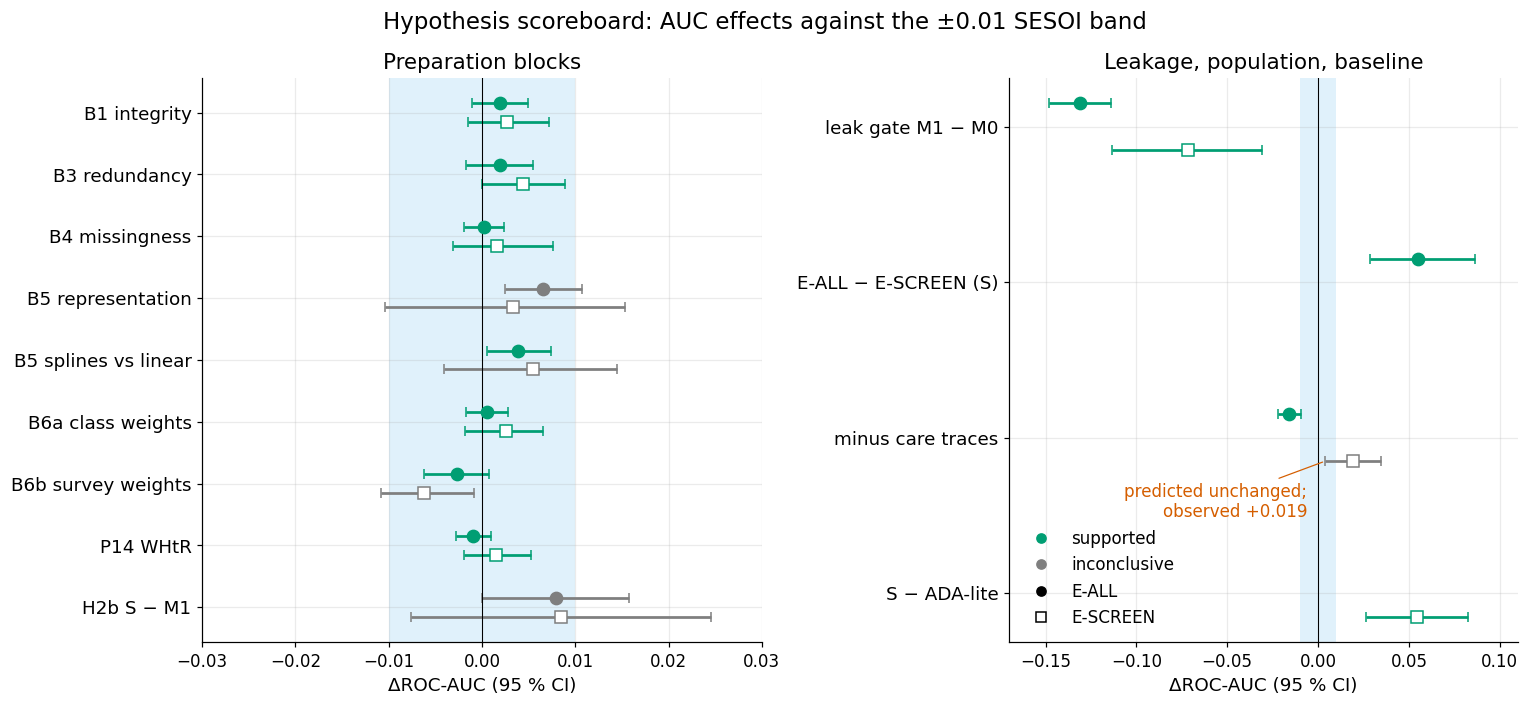

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5), gridspec_kw={"width_ratios": [1.1, 1]})
SEEN = set()
VCOL = {"supported": OI["green"], "equivalent": OI["blue"], "refuted": OI["vermillion"], "inconclusive": OI["grey"], "mixed": OI["purple"]}
LEFT = [("B1", "(a) AUC", "B1 integrity"), ("B3", "(a) AUC", "B3 redundancy"), ("B4", "(a) AUC", "B4 missingness"),
        ("B5", "(b) AUC block", "B5 representation"), ("B5", "(c) AUC splines", "B5 splines vs linear"),
        ("B6a", "(a) AUC", "B6a class weights"), ("B6b", "(a) unweighted AUC", "B6b survey weights"),
        ("P14", "(a) AUC", "P14 WHtR"), ("H2b", "(a) AUC", "H2b S − M1")]
RIGHT = [("B2", "(a) AUC M1-M0", "leak gate M1 − M0"), ("H2c", "(i) AUC E-ALL - E-SCREEN (S)", "E-ALL − E-SCREEN (S)"),
         ("H2c", "(ii) minus care, E-ALL", "minus care traces"), ("H2c", "(iii) S - ADA-lite, E-SCREEN", "S − ADA-lite")]
for ax, spec, ttl, lim in ((axes[0], LEFT, "Preparation blocks", (-0.03, 0.03)), (axes[1], RIGHT, "Leakage, population, baseline", (-0.17, 0.11))):
    ylabels = []
    for i, (h, sub, lab) in enumerate(spec):
        g = det[(det["hyp_id"] == h) & (det["sub"].str.startswith(sub[:4])) & (det["metric"] == "roc_auc") & (det["tier"] == 1)]
        if h == "H2c" and sub.startswith("(ii)"):
            g = det[(det["hyp_id"] == "H2c") & det["sub"].str.startswith("(ii)")]
        for _, r in g.iterrows():
            off = -0.15 if r["pop"] in ("E-ALL", "E-ALL minus E-SCREEN") else 0.15
            col = VCOL.get(r["verdict"], OI["grey"])
            SEEN.add(r["verdict"])
            ax.errorbar(r["est"], i + off, xerr=[[r["est"] - r["lo"]], [r["hi"] - r["est"]]], fmt="o" if off < 0 else "s",
                        color=col, mfc=col if off < 0 else "white", capsize=3, ms=8, lw=1.8)
            if h == "H2c" and r["pop"] == "E-SCREEN" and r["verdict"] == "inconclusive" and r["lo"] > 0:
                ax.annotate(f"predicted unchanged;\nobserved {r['est']:+.3f}", (r["lo"], i + off), xytext=(-12, -14), va="top",
                            textcoords="offset points", fontsize=11, color=OI["vermillion"], ha="right",
                            arrowprops=dict(arrowstyle="-", color=OI["vermillion"], lw=0.8))
        ylabels.append(lab)
    ax.axvspan(-0.01, 0.01, color=OI["sky"], alpha=0.18, lw=0)
    ax.axvline(0, color="k", lw=0.7)
    ax.set_yticks(range(len(spec)), ylabels, fontsize=12)
    ax.tick_params(axis="x", labelsize=11)
    ax.invert_yaxis()
    ax.set_xlim(lim)
    ax.set_title(ttl, fontsize=14)
    ax.set_xlabel("ΔROC-AUC (95 % CI)", fontsize=12)
from matplotlib.lines import Line2D
hand = [Line2D([], [], marker="o", ls="", color=c, label=v) for v, c in VCOL.items() if v in SEEN]
hand += [Line2D([], [], marker="o", ls="", color="k", label="E-ALL"), Line2D([], [], marker="s", ls="", color="k", mfc="white", label="E-SCREEN")]
axes[1].legend(handles=hand, fontsize=11, loc="lower left")
fig.suptitle("Hypothesis scoreboard: AUC effects against the ±0.01 SESOI band", fontsize=15)
fig.tight_layout()
plots.savefig(fig, "S10_scoreboard_forest", caption="F10-1. Paired ΔROC-AUC of the locked AUC sub-claims (Tier 1; filled = E-ALL, corrected t or "
              "bootstrap, the wider; hollow = E-SCREEN, bootstrap) with 95 % CIs, coloured by the sub-claim verdict under its locked rule; "
              "blue band = SESOI ±0.01. For equivalence claims 'supported' means the CI lies inside the band. Left: preparation blocks "
              "(leave-one-block-out) and the minimal-vs-systematic contrast; right: leakage gate, evaluation population, care traces and baseline.")
plt.show()

**So what.** Every preparation block sits inside or at the edge of the ±0.01 band, while removing leakage (−0.13) and
changing the evaluation population (+0.055) move AUC by 5–13 times the SESOI: what the analyst *includes* and *whom
the model is scored on* matter an order of magnitude more than how carefully admissible data are prepared. The one
sub-claim that missed its locked prediction although its CI excludes 0 – care items on E-SCREEN, predicted
"unchanged", observed +0.019 – is labelled in the figure.

## 3 Post-lock notes
**Why.** After the lock, later interpretations must be visible as such. Three entries are recorded in the §10
decision register (not in the locked file): the operational reading of H3, the source of the P14 verdict and the
verdict of H1b. The POST-LOCK M1 sensitivity is recorded in §7.12.1 and DR-S7-16.

In [6]:
POSTLOCK = [
    dict(item="H3 reading", note=("'Misses most' is read column-wise: within a diabetes stratum, which training label has the lowest recall "
                                  "(coded in fairness.h3_elements before the matrix was viewed). The row-wise reading – which stratum each label "
                                  f"misses most – is secondary: {lm['row_wise_min']}."),
         consequence=f"H3 {lm['verdict']} under the column-wise reading; the row-wise pattern is reported as a descriptive finding"),
    dict(item="P14 verdict", note=f"§7 entered P14 as '{S7V['P14']['verdict']}' with part (b) deferred; §8 combined (a) and (b)",
         consequence=f"scoreboard uses the §8 combined verdict: {get('S8:verdicts.P14')}"),
    dict(item="H1b verdict", note="§4 reported crude and standardised differences but no verdict line",
         consequence=f"locked rule applied here: standardised {h1b_std:+.2f} pp [{h1b_lo:+.2f}, {h1b_hi:+.2f}] < +2 pp and below crude -> {h1b_v}"),
]
show(pd.DataFrame(POSTLOCK))

item,note,consequence
H3 reading,"'Misses most' is read column-wise: within a diabetes stratum, which training label has the lowest recall (coded in fairness.h3_elements before the matrix was viewed). The row-wise reading – which stratum each label misses most – is secondary: {'L_self': 'Undiagnosed', 'L_A1c': 'Undiagnosed', 'L_comb': 'Undiagnosed'}.",H3 inconclusive under the column-wise reading; the row-wise pattern is reported as a descriptive finding
P14 verdict,§7 entered P14 as 'supported' with part (b) deferred; §8 combined (a) and (b),scoreboard uses the §8 combined verdict: inconclusive
H1b verdict,§4 reported crude and standardised differences but no verdict line,"locked rule applied here: standardised +0.69 pp [-2.56, +3.93] < +2 pp and below crude -> supported"


**So what.** None of the notes changes a locked statement or a stored estimate; they make explicit how two ambiguous
or deferred items were resolved.

## 4 Improvements and deteriorations
**Why.** The brief asks for improvements and deteriorations to be explained. A deterioration can be the correct outcome
(removing leakage) and an improvement an artefact (class weights at threshold 0.5); each row gives the mechanism,
the identifying test and the verdict.

In [7]:
lg = M["S7"]["leak_gate"]
hl = M["S7"]["headline"]
tm = M["S7"]["tree_m0"]
rw = pd.DataFrame(get("S8:reweighing.eod")).set_index(["arm", "group"]).sort_index()
blk = rw.loc[("S+RW(race)", "NH Black")]
asn = rw.loc[("S+RW(race)", "NH Asian")]
b6 = prim[prim["hyp_id"] == "B6a"].set_index("sub")
b5 = prim[prim["hyp_id"] == "B5"].set_index("sub")
ada = M["S7"]["ada_lr_minus_points"]["E-SCREEN"]
b6b_s = det[(det["hyp_id"] == "B6b") & (det["pop"] == "E-SCREEN")].iloc[0]


def ci3(e, lo, hi, k=3):
    return f"{e:+.{k}f} [{lo:+.{k}f}, {hi:+.{k}f}]"


IMPDET = pd.DataFrame([
    dict(change="Availability rule (M0 → M1)", direction="deterioration (correct)", metric="ΔAUC E-ALL / E-SCREEN",
         effect=f"{ci3(lg['T1_E-ALL']['est'], lg['T1_E-ALL']['lo'], lg['T1_E-ALL']['hi'])} / {ci3(lg['T1_E-SCREEN']['est'], lg['T1_E-SCREEN']['lo'], lg['T1_E-SCREEN']['hi'])}",
         mechanism="treatment and skip-logic items (DIQ070, DIQ180, DID040) exist only for people already diagnosed",
         test=f"tree root on M0 = {M['S7']['tree_roots']['M0']['variable']} (leak role); M1/S root {M['S7']['tree_roots']['S']['variable']}; §9 leak hunt not triggered",
         verdict=f"H2a {S7V['H2a']['verdict']}, B2 {S7V['B2']['verdict']}, B2t {S7V['B2t']['verdict']}"),
    dict(change="Naive median imputation (M0 tree)", direction="deterioration on screening", metric="tree AUC E-SCREEN M0 vs M1",
         effect=f"{tm['escreen_auc']['M0']:.3f} vs {tm['escreen_auc']['M1']:.3f}",
         mechanism=f"DID040 (age at diagnosis) {tm['did040_missing_share']:.0%} missing, filled with the median {tm['did040_fill']:.0f}: the split separates 'diagnosed' from 'imputed'",
         test="depth-3 tree on the M0 frame; level-2 split on DID040", verdict="descriptive (B2t probe)"),
    dict(change="Balanced class weights (B6a)", direction="deterioration (calibration) + artefactual gain", metric="ΔBrier / Δbalanced accuracy at 0.5",
         effect=f"{ci3(b6.loc['(b) Brier', 'est'], b6.loc['(b) Brier', 'lo'], b6.loc['(b) Brier', 'hi'])} / {ci3(b6.loc['(c) balanced accuracy at 0.5', 'est'], b6.loc['(c) balanced accuracy at 0.5', 'lo'], b6.loc['(c) balanced accuracy at 0.5', 'hi'])}",
         mechanism="re-weighting shifts every probability upward; ranking unchanged (ΔAUC "
                   f"{b6.loc['(a) AUC', 'est']:+.4f}); balanced accuracy at 0.5 rises only because 0.5 becomes a better threshold",
         test="leave-one-block-out, paired CV", verdict=f"B6a {S7V['B6a']['verdict']}; H2b(b) refuted"),
    dict(change="Systematic preparation without class weights (S−B6a vs M1)", direction="small improvement", metric="ΔAUC / ΔBrier E-ALL",
         effect=f"{ci3(pp_.loc[('E-ALL', 'roc_auc'), 'diff'], pp_.loc[('E-ALL', 'roc_auc'), 'lo'], pp_.loc[('E-ALL', 'roc_auc'), 'hi'])} / "
                f"{ci3(pp_.loc[('E-ALL', 'brier'), 'diff'], pp_.loc[('E-ALL', 'brier'), 'lo'], pp_.loc[('E-ALL', 'brier'), 'hi'], 4)}",
         mechanism="splines, scaling and pruning give the L2 model a better-posed problem (unscaled M1 hits the iteration limit in every fold)",
         test="paired bootstrap, exploratory (not locked)", verdict="below SESOI; not a verdict"),
    dict(change="Representation block (B5: Yeo-Johnson, scaling, splines)", direction="improvement (calibration)", metric="Δ|calibration slope − 1| E-ALL",
         effect=ci3(b5.loc['(a) |cal slope - 1|', 'est'], b5.loc['(a) |cal slope - 1|', 'lo'], b5.loc['(a) |cal slope - 1|', 'hi']),
         mechanism="mostly solver convergence once features are scaled; spline terms supported by the likelihood-ratio test",
         test=f"LR χ²({M['S7']['lr_test_splines']['1']['df']}) = {M['S7']['lr_test_splines']['1']['chi2']:.1f}", verdict=f"B5 {S7V['B5']['verdict']}"),
    dict(change="Removing care traces (T1-minus-care vs S)", direction="deterioration on E-ALL, improvement on E-SCREEN", metric="ΔAUC E-ALL / E-SCREEN",
         effect=f"{ci3(hl['minus_care_eall']['est'], hl['minus_care_eall']['lo'], hl['minus_care_eall']['hi'])} / {ci3(hl['minus_care_escreen']['est'], hl['minus_care_escreen']['lo'], hl['minus_care_escreen']['hi'])}",
         mechanism="told-high-blood-pressure and told-high-cholesterol items mark people already in care, who are mostly the diagnosed; among the not-yet-diagnosed they add noise",
         test="pre-registered ablation H2c(ii)", verdict="E-ALL supported; E-SCREEN rose (+0.019) instead of staying unchanged; its CI crosses the ±0.01 band (inconclusive)"),
    dict(change="ADA-lite items refitted by logistic regression (vs points)", direction="deterioration on E-SCREEN", metric="ΔAUC E-SCREEN",
         effect=ci3(ada['est'], ada['lo'], ada['hi']),
         mechanism="the refit learns L_comb, 84 % of whose positives are diagnosed: it optimises recognition, not screening",
         test="paired bootstrap", verdict="descriptive"),
    dict(change="Survey-weighted fit (B6b)", direction="small deterioration", metric="ΔAUC E-ALL / E-SCREEN (unweighted metric)",
         effect=f"{ci3(prim[prim['hyp_id'] == 'B6b'].iloc[0]['est'], prim[prim['hyp_id'] == 'B6b'].iloc[0]['lo'], prim[prim['hyp_id'] == 'B6b'].iloc[0]['hi'])} / "
                f"{ci3(b6b_s['est'], b6b_s['lo'], b6b_s['hi'])}",
         mechanism="weights re-target the population and cut the effective n (Kish deff ≈ 1.5)", test="non-inferiority at −0.01",
         verdict=f"B6b {S7V['B6b']['verdict']}"),
    dict(change="Race reweighing (fairness mitigation)", direction="deterioration (NH Black gap widens)", metric="ΔEOD NH Black / NH Asian",
         effect=f"{ci3(blk['d_eod'], blk['d_eod_lo'], blk['d_eod_hi'])} / {ci3(asn['d_eod'], asn['d_eod_lo'], asn['d_eod_hi'])}",
         mechanism=f"race weights range {get('S8:reweighing.weight_range.race')[0]:.2f}–{get('S8:reweighing.weight_range.race')[1]:.2f} (NH Black cases down-weighted most); "
                   "rebalancing prevalence moves the shared threshold away from the Black positives",
         test="paired bootstrap of EOD change", verdict="not adopted"),
])
show(IMPDET[["change", "direction", "effect", "mechanism", "verdict"]])
IMPDET.to_csv(OUT / "improvements_deteriorations.csv", index=False)

change,direction,effect,mechanism,verdict
Availability rule (M0 → M1),deterioration (correct),"-0.131 [-0.148, -0.114] / -0.072 [-0.113, -0.031]","treatment and skip-logic items (DIQ070, DIQ180, DID040) exist only for people already diagnosed","H2a supported, B2 supported, B2t supported"
Naive median imputation (M0 tree),deterioration on screening,0.633 vs 0.701,"DID040 (age at diagnosis) 86% missing, filled with the median 50: the split separates 'diagnosed' from 'imputed'",descriptive (B2t probe)
Balanced class weights (B6a),deterioration (calibration) + artefactual gain,"+0.076 [+0.068, +0.084] / +0.145 [+0.123, +0.166]",re-weighting shifts every probability upward; ranking unchanged (ΔAUC +0.0006); balanced accuracy at 0.5 rises only because 0.5 becomes a better threshold,B6a supported; H2b(b) refuted
Systematic preparation without class weights (S−B6a vs M1),small improvement,"+0.007 [+0.000, +0.015] / -0.0018 [-0.0036, -0.0000]","splines, scaling and pruning give the L2 model a better-posed problem (unscaled M1 hits the iteration limit in every fold)",below SESOI; not a verdict
"Representation block (B5: Yeo-Johnson, scaling, splines)",improvement (calibration),"-0.039 [-0.068, -0.010]",mostly solver convergence once features are scaled; spline terms supported by the likelihood-ratio test,B5 inconclusive
Removing care traces (T1-minus-care vs S),"deterioration on E-ALL, improvement on E-SCREEN","-0.016 [-0.022, -0.009] / +0.019 [+0.004, +0.034]","told-high-blood-pressure and told-high-cholesterol items mark people already in care, who are mostly the diagnosed; among the not-yet-diagnosed they add noise",E-ALL supported; E-SCREEN rose (+0.019) instead of staying unchanged; its CI crosses the ±0.01 band (inconclusive)
ADA-lite items refitted by logistic regression (vs points),deterioration on E-SCREEN,"-0.018 [-0.032, -0.002]","the refit learns L_comb, 84 % of whose positives are diagnosed: it optimises recognition, not screening",descriptive
Survey-weighted fit (B6b),small deterioration,"-0.003 [-0.006, +0.001] / -0.006 [-0.011, -0.001]",weights re-target the population and cut the effective n (Kish deff ≈ 1.5),B6b supported
Race reweighing (fairness mitigation),deterioration (NH Black gap widens),"-0.033 [-0.086, -0.003] / -0.018 [-0.093, +0.053]",race weights range 0.70–1.16 (NH Black cases down-weighted most); rebalancing prevalence moves the shared threshold away from the Black positives,not adopted


**So what.** The biggest change is a *correct deterioration*: the availability rule costs 0.13 AUC because that AUC
was leakage. The biggest *improvement* (balanced accuracy +0.14) is a class-weight artefact that worsens Brier by
0.076 (B6a block, S − S−B6a; the S − M1 Brier gap is +0.074); without class weights, systematic preparation gains
0.007 AUC and no calibration cost. Dropping care traces
lowers whole-sample AUC but raises screening AUC, and refitting ADA items on our label lowers screening AUC – both say
the label rewards *recognising the diagnosed*. Race reweighing widens the NH Black gap and was not adopted.

## 5 What the ML evidence says about the data
**Why.** The project uses simple models as instruments that measure properties of the data; each row names the
property, the probe, the reading, the number and the evidence grade.

In [8]:
s3 = M["S3"]["blanket_recode"]
mask = M["S5"]["masking"]
cal = pd.DataFrame(get("S8:calibration.table")).set_index("group")
eod = pd.DataFrame(get("S8:eod_eall_t1")).set_index("group")
perm9 = M["S9"]["permutation"]
gdec = M["S8"]["gap_decomposition"]
flips = pd.DataFrame(get("S4:simpson.flips"))
n_med_flip = int((flips["role"] == "mediator").sum())
mnar = M["S9"]["mnar"]
dp = pd.DataFrame(mnar["delta_prevalence"]).set_index("odds_ratio")
WHAT = pd.DataFrame([
    dict(property="Skip-logic leakage", probe="leak gate M0 → M1; depth-3 tree root",
         reading="the naive model's high AUC is a questionnaire-design artefact",
         number=f"AUC {hl['auc_M0_eall_T1']:.3f} → {hl['auc_M1_eall_T1']:.3f}; ΔAUC {ci3(lg['T1_E-ALL']['est'], lg['T1_E-ALL']['lo'], lg['T1_E-ALL']['hi'])}; root {M['S7']['tree_roots']['M0']['variable']}",
         grade="E2"),
    dict(property="Imputation artefact", probe="M0 tree level-2 split",
         reading="a tree learns an imputation constant as if it were biology",
         number=f"DID040 {tm['did040_missing_share']:.0%} missing → {tm['did040_fill']:.0f}; tree E-SCREEN AUC {tm['escreen_auc']['M0']:.3f} vs {tm['escreen_auc']['M1']:.3f}",
         grade="E1"),
    dict(property="Blanket sentinel cleaning", probe="per-variable vs blanket recode",
         reading="cleaning itself destroys information and labels",
         number=f"{s3['valid_cells_destroyed_cohort']:,} valid cells; {s3['a1c_positives_lost']}/{s3['a1c_positives']} HbA1c positives; {s3['l_comb_flips']}/{s3['l_comb_positives']} L_comb flips",
         grade="E1"),
    dict(property="Structural redundancy", probe="bootstrap SD of the BMI coefficient",
         reading="redundancy destabilises explanation, not prediction; L2 + scaling absorb most of it",
         number=f"SD ratio unscaled {cs['ratio_cumulative']['ratio']:.2f}, inside scaled L2 {cs['ratio_B3']['ratio']:.2f}; ΔAUC B3 "
                f"{prim[(prim['hyp_id'] == 'B3') & (prim['sub'] == '(a) AUC')].iloc[0]['est']:+.4f}",
         grade="E3"),
    dict(property="Spectrum / label composition", probe="same predictions scored on E-ALL and E-SCREEN",
         reading="whole-sample AUC measures recognition of known diabetes",
         number=f"S {hl['auc_S_eall_T1']:.3f} vs {hl['auc_S_escreen_T1']:.3f}; gap {ci3(hl['eall_minus_escreen_S_T1']['est'], hl['eall_minus_escreen_S_T1']['lo'], hl['eall_minus_escreen_S_T1']['hi'])}",
         grade="E2"),
    dict(property="Care traces", probe="T1-minus-care ablation on both populations",
         reading="contact-with-care items help recognition and hinder screening",
         number=f"E-ALL {hl['minus_care_eall']['est']:+.3f}; E-SCREEN {ci3(hl['minus_care_escreen']['est'], hl['minus_care_escreen']['lo'], hl['minus_care_escreen']['hi'])}",
         grade="E3"),
    dict(property="Label is a measurement", probe="3 × 3 label matrix; treatment masking",
         reading="each label misses different people; no label lets these features find the undiagnosed",
         number=f"masking {mask['below_6_5']}/{mask['self_reported']} ({mask['below_6_5_share']:.1%}); recall Undiagnosed "
                f"{lm['recall']['Undiagnosed']['L_self']:.2f}/{lm['recall']['Undiagnosed']['L_A1c']:.2f}/{lm['recall']['Undiagnosed']['L_comb']:.2f}",
         grade="E3"),
    dict(property="Diagnosis gap by access", probe="model TPR diagnosed vs undiagnosed; group decomposition",
         reading="the model inherits who has been diagnosed",
         number=f"TPR diagnosed {gdec['tpr_diagnosed']:.2f} vs undiagnosed {gdec['tpr_undiagnosed']:.2f}; r(group TPR, care-trace share) {gdec['r_tpr_care_trace']:.2f}",
         grade="E3"),
    dict(property="BMI measurement bias", probe="single-feature AUC WHtR vs BMI; Asian TPR gap",
         reading="BMI under-measures adiposity in Asian adults; the full model only partly compensates",
         number=f"Asian gain {get('S5:asian_bmi.auc.NH Asian|WHtR − BMI (paired).auc'):+.3f} vs White {get('S5:asian_bmi.auc.NH White|WHtR − BMI (paired).auc'):+.3f}; "
                f"EOD Asian {eod.loc['NH Asian', 'eod']:+.3f} [{eod.loc['NH Asian', 'eod_lo']:+.3f}, {eod.loc['NH Asian', 'eod_hi']:+.3f}]",
         grade="E3 (Asian cells exploratory)"),
    dict(property="Calibration across groups", probe="observed : expected by race",
         reading="a race-blind model is calibrated on average, not within race",
         number="O:E " + ", ".join(f"{g} {cal.loc[g, 'oe']:.2f}" for g in ["NH White", "NH Black", "NH Asian", "Mexican American"]),
         grade="E3"),
    dict(property="Procedure credibility", probe="label permutation; positive control",
         reading="no procedural leakage; weak real signal is detectable (does not exclude feature leakage)",
         number=f"null mean M1 {perm9['M1']['null_mean']:.4f}, S {perm9['S']['null_mean']:.4f}; synthetic AUC-0.60 feature detected "
                f"({sum(r['detected'] for r in M['S9']['positive_control']['rows'])}/{len(M['S9']['positive_control']['rows'])})",
         grade="E1"),
    dict(property="Missing HbA1c", probe="IPW and delta-adjusted (MNAR) prevalence; S − M1 under MNAR",
         reading="missingness is not ignorable in principle but barely moves prevalence or the comparison",
         number=f"prevalence {dp.loc[1.0, 'prevalence']:.1%} (MAR) to {dp.iloc[-1]['prevalence']:.1%} at odds ratio {dp.index[-1]:.0f}; Manski [{mnar['manski'][0]:.1%}, {mnar['manski'][1]:.1%}]",
         grade="E3"),
])
show(WHAT)
WHAT.to_csv(OUT / "what_ml_says.csv", index=False)

property,probe,reading,number,grade
Skip-logic leakage,leak gate M0 → M1; depth-3 tree root,the naive model's high AUC is a questionnaire-design artefact,"AUC 0.961 → 0.828; ΔAUC -0.131 [-0.148, -0.114]; root DIQ070",E2
Imputation artefact,M0 tree level-2 split,a tree learns an imputation constant as if it were biology,DID040 86% missing → 50; tree E-SCREEN AUC 0.633 vs 0.701,E1
Blanket sentinel cleaning,per-variable vs blanket recode,cleaning itself destroys information and labels,"1,496 valid cells; 29/721 HbA1c positives; 6/971 L_comb flips",E1
Structural redundancy,bootstrap SD of the BMI coefficient,"redundancy destabilises explanation, not prediction; L2 + scaling absorb most of it","SD ratio unscaled 2.87, inside scaled L2 1.36; ΔAUC B3 +0.0019",E3
Spectrum / label composition,same predictions scored on E-ALL and E-SCREEN,whole-sample AUC measures recognition of known diabetes,"S 0.836 vs 0.781; gap +0.055 [+0.028, +0.086]",E2
Care traces,T1-minus-care ablation on both populations,contact-with-care items help recognition and hinder screening,"E-ALL -0.016; E-SCREEN +0.019 [+0.004, +0.034]",E3
Label is a measurement,3 × 3 label matrix; treatment masking,each label misses different people; no label lets these features find the undiagnosed,masking 250/819 (30.5%); recall Undiagnosed 0.50/0.56/0.52,E3
Diagnosis gap by access,model TPR diagnosed vs undiagnosed; group decomposition,the model inherits who has been diagnosed,"TPR diagnosed 0.70 vs undiagnosed 0.52; r(group TPR, care-trace share) 0.63",E3
BMI measurement bias,single-feature AUC WHtR vs BMI; Asian TPR gap,BMI under-measures adiposity in Asian adults; the full model only partly compensates,"Asian gain +0.137 vs White +0.049; EOD Asian -0.184 [-0.343, -0.014]",E3 (Asian cells exploratory)
Calibration across groups,observed : expected by race,"a race-blind model is calibrated on average, not within race","O:E NH White 0.88, NH Black 1.30, NH Asian 1.35, Mexican American 1.39",E3


**So what.** Read top to bottom, the table is the project's argument: the data carry their *collection process* –
skip patterns, imputation constants, sentinel codes, who has been diagnosed, which body-size measure was taken – and
an unexamined model learns that process instead of diabetes. Probes that cost nothing in sophistication (a depth-3
tree, an ablation, a second evaluation population) expose more than any gain in AUC would.

## 6 Headline findings
**Why.** The video carries three findings, each backed by at least two independent lines of evidence; one is chosen
as the headline non-obvious modelling finding.

In [9]:
pc = pd.DataFrame(M["S9"]["positive_control"]["rows"])
HO = M["S9"].get("holdout", {})
HO_OK = "metrics" in HO
if HO_OK:
    HOM = pd.DataFrame(HO["metrics"]).set_index(["arm", "tier", "pop"]).sort_index()
    HOP = pd.DataFrame(HO["pairs"]).set_index(["comparison", "pop"]).sort_index()
print(f"hold-out available: {HO_OK}" + ("" if HO_OK else f" ({HO.get('status', 'missing')})"))
F = {
    "F1 Leakage and naive cleaning": [
        f"leak gate ΔAUC {ci3(lg['T1_E-ALL']['est'], lg['T1_E-ALL']['lo'], lg['T1_E-ALL']['hi'])} (E-SCREEN {lg['T1_E-SCREEN']['est']:+.3f})",
        f"M0 tree splits on {M['S7']['tree_roots']['M0']['variable']} then on DID040 = median {tm['did040_fill']:.0f} ({tm['did040_missing_share']:.0%} missing); "
        f"tree E-SCREEN AUC M0 {tm['escreen_auc']['M0']:.3f} < M1 {tm['escreen_auc']['M1']:.3f}",
        f"blanket recode destroys {s3['valid_cells_destroyed_cohort']:,} valid cells; {s3['a1c_positives_lost']} vs {s3['l_comb_flips']} label flips (HbA1c-only vs frozen L_comb)",
        f"§9 leak hunt on admissible arms: not triggered (max single-feature AUC {M['S9']['leak_hunt']['strongest_admissible']['auc']:.3f})"]
    + ([f"hold-out M1 − M0 {ci3(HOP.loc[('M1 T1 - M0 T1', 'E-ALL'), 'est'], HOP.loc[('M1 T1 - M0 T1', 'E-ALL'), 'lo'], HOP.loc[('M1 T1 - M0 T1', 'E-ALL'), 'hi'])}"] if HO_OK else []),
    "F2 Fallacies and measurement of performance": [
        f"insurance gap {ins['crude']:+.1f} → {ins['std']:+.1f} pp after age standardisation (attenuation)",
        f"Asian − White {get('S4:standardisation.asian_white.crude'):+.1f} → {get('S4:standardisation.asian_white.std'):+.1f} pp, both CIs include 0",
        f"BMI is a mediator in the DAG; {n_med_flip} of {len(flips)} Simpson sign flips come from mediator stratifiers",
        f"spectrum gap E-ALL − E-SCREEN {ci3(hl['eall_minus_escreen_S_T1']['est'], hl['eall_minus_escreen_S_T1']['lo'], hl['eall_minus_escreen_S_T1']['hi'])}",
        f"care-trace reversal: E-ALL {hl['minus_care_eall']['est']:+.3f}, E-SCREEN {ci3(hl['minus_care_escreen']['est'], hl['minus_care_escreen']['lo'], hl['minus_care_escreen']['hi'])}"],
    "F3 Label and measurement bias": [
        f"treatment masking {mask['below_6_5']}/{mask['self_reported']} = {mask['below_6_5_share']:.1%} ({mask['below_6_5_on_med']} on medication)",
        f"undiagnosed risk difference uninsured − insured {rd['rd_pp']:+.1f} pp [{rd['ci_low_pp']:.1f}, {rd['ci_high_pp']:.1f}]",
        f"3 × 3 matrix: H3 {lm['verdict']}; Undiagnosed is the lowest-recall stratum for every training label",
        f"NH Asian TPR gap {eod.loc['NH Asian', 'eod']:+.3f} [{eod.loc['NH Asian', 'eod_lo']:+.3f}, {eod.loc['NH Asian', 'eod_hi']:+.3f}], race permutation p {get('S8:permutation_eall_t1[attribute=race].p_value'):.3f}",
        f"WHtR − BMI single-feature gain difference Asian − White {gd['est']:+.3f} [{gd['psu_ci_low']:+.3f}, {gd['psu_ci_high']:+.3f}]",
        "calibration O:E by race " + ", ".join(f"{g} {cal.loc[g, 'oe']:.2f}" for g in ["NH White", "NH Black", "NH Asian", "Mexican American"])],
}
for k, v in F.items():
    print(k)
    for line in v:
        print("   -", line)

# headline: whole-sample AUC measures recognition of known diabetes, not screening
HEAD_LINES = [
    ("pre-registered spectrum gap (H2c-i, supported)", f"{ci3(hl['eall_minus_escreen_S_T1']['est'], hl['eall_minus_escreen_S_T1']['lo'], hl['eall_minus_escreen_S_T1']['hi'])}"),
    ("care-trace ablation changes sign between populations (H2c-ii)", f"E-ALL {hl['minus_care_eall']['est']:+.3f} vs E-SCREEN {hl['minus_care_escreen']['est']:+.3f}"),
    ("ADA items refitted on L_comb lose screening AUC", f"{ada['est']:+.3f} [{ada['lo']:+.3f}, {ada['hi']:+.3f}]"),
    ("§8 TPR: diagnosed vs undiagnosed positives at the same threshold", f"{gdec['tpr_diagnosed']:.2f} vs {gdec['tpr_undiagnosed']:.2f}"),
    ("§8 3 × 3 matrix: Undiagnosed column lowest under every label", str(lm["row_wise_min"])),
    ("leakage also is recognition: the leak gate is smaller on E-SCREEN", f"{lg['T1_E-ALL']['est']:+.3f} vs {lg['T1_E-SCREEN']['est']:+.3f}"),
]
if HO_OK:
    s_all, s_scr = HOM.loc[("S", 1, "E-ALL"), "roc_auc"], HOM.loc[("S", 1, "E-SCREEN"), "roc_auc"]
    HEAD_LINES.append(("hold-out, arm S: same direction and size (not separately testable, 25 screening positives)",
                       f"E-ALL {s_all:.3f} vs E-SCREEN {s_scr:.3f} (gap {s_all - s_scr:+.3f} vs {hl['eall_minus_escreen_S_T1']['est']:+.3f} in CV)"))
print("\nHEADLINE – whole-sample AUC measures recognition of known diabetes, not screening; distinct evidence lines:")
for a, b in HEAD_LINES:
    print(f"   - {a}: {b}")
S10["headline"] = dict(finding="Whole-sample AUC measures recognition of known diabetes, not screening",
                       n_evidence_lines=len(HEAD_LINES), lines=[f"{a}: {b}" for a, b in HEAD_LINES])
S10["findings"] = F
HF = pd.DataFrame([dict(finding=k, order=i + 1, evidence=line) for k, v in F.items() for i, line in enumerate(v)]
                  + [dict(finding="HEADLINE " + S10["headline"]["finding"], order=i + 1, evidence=f"{x}: {y}") for i, (x, y) in enumerate(HEAD_LINES)])
HF.to_csv(OUT / "headline_findings.csv", index=False)   # slide material for the three video findings

hold-out available: True
F1 Leakage and naive cleaning
   - leak gate ΔAUC -0.131 [-0.148, -0.114] (E-SCREEN -0.072)
   - M0 tree splits on DIQ070 then on DID040 = median 50 (86% missing); tree E-SCREEN AUC M0 0.633 < M1 0.701
   - blanket recode destroys 1,496 valid cells; 29 vs 6 label flips (HbA1c-only vs frozen L_comb)
   - §9 leak hunt on admissible arms: not triggered (max single-feature AUC 0.706)
   - hold-out M1 − M0 -0.117 [-0.144, -0.092]
F2 Fallacies and measurement of performance
   - insurance gap +5.3 → +0.7 pp after age standardisation (attenuation)
   - Asian − White -0.8 → +2.1 pp, both CIs include 0
   - BMI is a mediator in the DAG; 4 of 6 Simpson sign flips come from mediator stratifiers
   - spectrum gap E-ALL − E-SCREEN +0.055 [+0.028, +0.086]
   - care-trace reversal: E-ALL -0.016, E-SCREEN +0.019 [+0.004, +0.034]
F3 Label and measurement bias
   - treatment masking 250/819 = 30.5% (165 on medication)
   - undiagnosed risk difference uninsured − insured +23.2 pp

**So what – choice of the headline.** The modelling headline is **"a whole-sample AUC measures recognition of known
diabetes, not screening"** – spectrum bias (Ransohoff & Feinstein 1978) created by the label's composition (84 % of
positives already diagnosed), not by the model. It is non-obvious (one whole-sample AUC hides it), carried by six
evidence lines from §7–§8 (the hold-out shows the same direction and size, +0.060 vs +0.055, but is not separately
testable with 25 screening positives), and actionable (report E-SCREEN; keep care traces out of screening models).
Its pre-registered core H2c(i) is supported; H2c as a whole is inconclusive because the care-trace sub-claim (ii) on
E-SCREEN rose (+0.019) instead of staying unchanged, with a CI that crosses the ±0.01 band.

**Non-obvious pattern found through systematic profiling and EDA** (the brief's requirement): the sentinel profiling
of §3 found that a blanket 7/9/77/99 recode deletes valid HbA1c values of exactly 7.0 % and 9.0 % – 29 HbA1c-defined positives –
and the §7.5 tree probe showed that median imputation turns the skip-pattern item "age at diagnosis" into a constant
that codes the label. Both are invisible to summary statistics and are the leakage and naive-cleaning finding (F1).

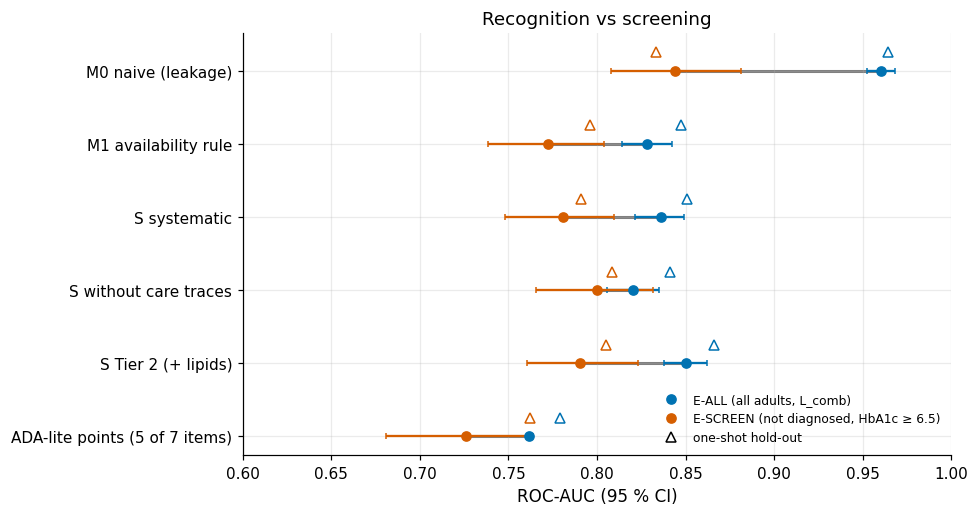

In [10]:
fig, ax = plt.subplots(figsize=(9, 4.8))
am = pd.DataFrame(M["S7"]["arm_metrics"]).set_index(["arm", "tier", "model"])
bl = M["S7"]["baselines"]
ARMS_FIG = [("M0", 1, "M0 naive (leakage)"), ("M1", 1, "M1 availability rule"), ("S", 1, "S systematic"),
            ("T1-minus-care", 1, "S without care traces"), ("S", 2, "S Tier 2 (+ lipids)")]
for i, (a, t, lab) in enumerate(ARMS_FIG):
    r = am.loc[(a, t, "lr")]
    ax.plot([r["escr_auc"], r["eall_auc"]], [i, i], color=OI["grey"], lw=2, zorder=1)
    ax.errorbar(r["eall_auc"], i, xerr=[[r["eall_auc"] - r["eall_auc_lo"]], [r["eall_auc_hi"] - r["eall_auc"]]], fmt="o", color=OI["blue"], capsize=2, zorder=2)
    ax.errorbar(r["escr_auc"], i, xerr=[[r["escr_auc"] - r["escr_auc_lo"]], [r["escr_auc_hi"] - r["escr_auc"]]], fmt="o", color=OI["vermillion"], capsize=2, zorder=2)
    if HO_OK and (a, t, "E-ALL") in HOM.index:
        ax.plot(HOM.loc[(a, t, "E-ALL"), "roc_auc"], i - 0.25, "^", color=OI["blue"], mfc="white", ms=6)
        ax.plot(HOM.loc[(a, t, "E-SCREEN"), "roc_auc"], i - 0.25, "^", color=OI["vermillion"], mfc="white", ms=6)
j = len(ARMS_FIG)
ada_p = bl["BL-ADAlite (points)"]
ax.errorbar(ada_p["escr_auc"], j, xerr=[[ada_p["escr_auc"] - ada_p["lo"]], [ada_p["hi"] - ada_p["escr_auc"]]], fmt="o", color=OI["vermillion"], capsize=2)
ax.plot(ada_p["eall_auc"], j, "o", color=OI["blue"])
ax.plot([ada_p["escr_auc"], ada_p["eall_auc"]], [j, j], color=OI["grey"], lw=2, zorder=0)
if HO_OK:
    for pop_, col_ in (("E-ALL", OI["blue"]), ("E-SCREEN", OI["vermillion"])):
        ax.plot(HOM.loc[("BL-ADAlite", 1, pop_), "roc_auc"], j - 0.25, "^", color=col_, mfc="white", ms=6)
ax.set_yticks(range(j + 1), [l for _, _, l in ARMS_FIG] + ["ADA-lite points (5 of 7 items)"])
ax.invert_yaxis()
leg = [Line2D([], [], marker="o", ls="", color=OI["blue"], label="E-ALL (all adults, L_comb)"),
       Line2D([], [], marker="o", ls="", color=OI["vermillion"], label="E-SCREEN (not diagnosed, HbA1c ≥ 6.5)")]
if HO_OK:
    leg.append(Line2D([], [], marker="^", ls="", color="k", mfc="white", label="one-shot hold-out"))
ax.legend(handles=leg, fontsize=8, loc="lower right")
ax.set(xlabel="ROC-AUC (95 % CI)", xlim=(0.6, 1.0), title="Recognition vs screening")
fig.tight_layout()
plots.savefig(fig, "S10_recognition_vs_screening", caption="F10-2. The same out-of-fold predictions scored on E-ALL (blue; all adults, 84 % of "
              "positives already diagnosed) and E-SCREEN (red; adults without a diagnosis, positive = HbA1c ≥ 6.5 %), training part, 95 % "
              "bootstrap CIs; triangles = one-shot hold-out where available. Every arm loses AUC on the screening population; the arm without "
              "care-trace items is the only one that ranks higher on E-SCREEN than arm S.")
plt.show()

**So what.** The grey bars are the price of moving from "recognise the diagnosed" to "find the undiagnosed": about 0.12
for M0, about 0.055 for the admissible arms, and only 0.02 for the arm without care traces – the best screening
model although the worst on E-ALL.

## 7 Claims ledger
**Why.** Every statement for the summary or the video becomes a row of `governance/claims.csv` with grade, evidence,
CI, robustness, external reference, scope, falsifier and video segment. Enforced in code: at most 25 words; the verb
follows the grade; no causal verbs; a **headline** claim with fewer than two independent evidence lines is
downgraded automatically.

In [11]:
LADDER = {"E1": "confirms that", "E2": "shows that", "E3": "is consistent with the view that", "E4": "suggests that"}
CAUSAL = re.compile(r"\b(caus\w*|drive[sn]?|driven|leads? to|results? in|due to|because|impact\w*|effect of|prevent\w*)\b", re.I)
VSEG = {"V1": "0:00-1:30 scope and design", "V2": "1:30-2:15 cost of naive cleaning", "V3": "2:15-3:30 leakage gate",
        "V4": "3:30-4:30 redundancy and skew", "V5": "4:30-6:00 fallacies", "V6": "6:00-8:30 label and measurement bias",
        "V7": "8:30-10:15 models and evaluation", "V8": "10:15-11:20 what ML says about the data"}
sm = M["S9"]["summary"]["table"]
sm_e = {r["check"]: r for r in sm if r["pop"] == "E-ALL"}
pick = lambda suf: next(v for k, v in sm_e.items() if k.endswith(suf))   # labels carry the run's counts (FAST 5 seeds / 30 specs)
N_SEEDS, N_CURVE = M["S9"]["seeds"]["n"], M["S9"]["specification_curve"]["n"]
N_SENS = int(pick("sensitivity specs")["check"].split()[0])
ROB_H2B = (f"{N_SEEDS} seeds {pick('CV seeds')['verdicts']}; {N_SENS} specs {pick('sensitivity specs')['verdicts']}; "
           f"{N_CURVE}-spec curve {pick('-spec curve')['verdicts']}; PSU-grouped CV {sm_e['strata x PSU grouped CV']['verdicts']}; "
           f"IPW {sm_e['IPW (evaluation; fit + evaluation)']['verdicts']}")
ROB_LEAK = (f"own-C tuning gives the same gate {M['S9']['sensitivity']['leak_gate_own_C']['E-ALL']['est']:+.3f}; permutation null "
            f"{perm9['M1']['null_mean']:.3f}; leak hunt not triggered")
ROB_NONE = "not varied in §9 (single specification)"
db = M["S4"]["db516"]
v2 = pd.DataFrame(M["S9"]["external"]["v2"]).set_index("quantity")
v2d = v2.loc["definition effect C - B"]
ADA_ITEMS, ADA_MISS = get("S1:ada_lite.items"), get("S1:ada_lite.missing")
PUB_DB516 = {"total": 15.8, "diagnosed": 11.3, "undiagnosed": 4.5}   # published NCHS Data Brief 516 (external reference)
EXT_DB = (f"NCHS DB516: reproduced {db['total']:.2f}/{db['diagnosed']:.2f}/{db['undiagnosed']:.2f} % vs published "
          f"{PUB_DB516['total']}/{PUB_DB516['diagnosed']}/{PUB_DB516['undiagnosed']}")
sw = lambda r: f"{r['est']:+.3f} [{r['lo']:+.3f}, {r['hi']:+.3f}]"
und = get("S5:undiagnosed_meaning.contact.blood test past 3 years (DIQ180=1)")
pe = lambda h: HYP.loc[h, "prior"]
eod_b = rw.loc[("S+RW(race)", "NH Black")]
whtr_a = get("S5:asian_bmi.auc.NH Asian|WHtR − BMI (paired).auc")
whtr_w = get("S5:asian_bmi.auc.NH White|WHtR − BMI (paired).auc")
max_lab_diff = float(h3c["est"].abs().max())
hx = h3c.loc[h3c["est"].abs().idxmax()]
fx = flips[flips["role"] == "mediator"].iloc[0]
oe_lo = min(cal.loc[g, "oe"] for g in ["NH Black", "NH Asian", "Mexican American"])
oe_hi = max(cal.loc[g, "oe"] for g in ["NH Black", "NH Asian", "Mexican American"])
std_tab = pd.read_csv(C.RESULTS_DIR / "S4" / "std_differences.csv")
std_ins = std_tab[std_tab["contrast"] == "insured − uninsured"]["std"]
std_asw = std_tab[std_tab["contrast"] == "NH Asian − NH White"]["std"]
adj_u = get("S5:undiagnosed_inequality.adjusted_logit.uninsured")
told_bl = get("S5:undiagnosed_meaning.contact.told borderline (DIQ010=3)")
asian_pos_train = int(get("S8:group_sizes[group=NH Asian].pos_eall"))
asian_n = int(get("S5:representation.shares.race|NH Asian.n"))
uninsured_n = int(get("S5:undiagnosed_inequality.proportions.uninsured.n"))
asian_whtr_n = int(get("S5:asian_bmi.auc.NH Asian|WHtR.n"))
sum9 = {r["check"]: r["verdicts"] for r in M["S9"]["summary"]["table"] if r["pop"] == "E-ALL"}
top10_pass = sum(r["verdict"] == "PASS" for r in M["S9"]["leak_hunt"]["top10"])

CL = [
    dict(cid="C01", vs="V3", head=True, grade="E2", type="leakage", subj="The leak gate",
         prop=f"removing inadmissible items (treatment, diagnosis history, glucose testing) lowers E-ALL AUC by {-lg['T1_E-ALL']['est']:.2f}, and the excess was leakage",
         ev=["§7 paired CV leak gate (H2a/B2)", "§7 depth-3 tree root on a treatment item (B2t)", "§9 leak hunt on admissible arms", "§9 permutation null"]
            + (["§9 one-shot hold-out M1 − M0"] if HO_OK else []),
         eff=f"ΔAUC M1 − M0 E-ALL {sw(lg['T1_E-ALL'])}; E-SCREEN {sw(lg['T1_E-SCREEN'])}", prereg=pe("H2a"),
         rob=ROB_LEAK + (f"; hold-out {sw(HOP.loc[('M1 T1 - M0 T1', 'E-ALL')])}" if HO_OK else ""), ext="none",
         scope="training part, Tier 1, E-ALL", fals="CI of M1 − M0 reaching above −0.05", hyp="H2a;B2;B2t"),
    dict(cid="C02", vs="V3", head=False, grade="E1", type="data_artefact", subj="The naive tree",
         prop=f"median imputation turns age at diagnosis ({tm['did040_missing_share']:.0%} missing) into a constant {tm['did040_fill']:.0f} that the tree splits on",
         ev=["§7 tree structure of M0"], eff=f"fill {tm['did040_fill']:.0f}; tree E-SCREEN AUC M0 {tm['escreen_auc']['M0']:.3f} vs M1 {tm['escreen_auc']['M1']:.3f} (descriptive)",
         prereg="none (tree probe B2t)", rob=ROB_NONE, ext="none", scope="M0 frame, training part", fals="M0 tree without a DID040 split", hyp="B2t"),
    dict(cid="C03", vs="V2", head=False, grade="E1", type="cleaning_cost", subj="The sentinel audit",
         prop=f"a blanket 7/9/77/99 recode destroys {s3['valid_cells_destroyed_cohort']:,} valid cells and {s3['a1c_positives_lost']} of {s3['a1c_positives']} HbA1c-positive labels",
         ev=["§3.3–§3.4 per-variable vs blanket recode counts", f"§6 label rebuilt from naive data ({M['S6']['B1']['naive_lcomb_pos']} vs {s3['l_comb_positives']} positives)"],
         eff=f"{s3['valid_cells_destroyed_cohort']:,} cells; {s3['a1c_positives_lost']}/{s3['a1c_positives']}; L_comb flips {s3['l_comb_flips']}/{s3['l_comb_positives']}",
         prereg="analysis_seen", rob="deterministic count", ext="NHANES codebooks (sentinels only on questionnaire items)", scope="cohort 5,730",
         fals="a recount giving a different number", hyp="B1"),
    dict(cid="C04", vs="V2", head=False, grade="E2", type="fidelity", subj="Leave-one-block-out ablation",
         prop=f"repairing XPT zeros and sentinels changes E-ALL AUC by only {prim[(prim['hyp_id'] == 'B1')].iloc[0]['est']:+.3f}: justified by fidelity, not performance",
         ev=["§7 paired CV B1", "§7 E-SCREEN and Tier 2 replicates"], eff=f"ΔAUC {sw(prim[prim['hyp_id'] == 'B1'].iloc[0])}",
         prereg=pe("B1"), rob="same verdict on E-SCREEN and Tier 2", ext="none", scope="training part", fals="CI wholly beyond ±0.01", hyp="B1"),
    dict(cid="C05", vs="V7", head=True, grade="E3", type="minimal_vs_systematic", subj="The M1-versus-S contrast",
         prop=f"systematic preparation changes AUC by under {h2b.loc['(a) AUC', 'hi']:.3f}; equivalence stays unestablished (MDD {h2b.loc['(a) AUC', 'mdd']:.3f})",
         ev=["§7 paired CV H2b(a)", f"§9 {N_SEEDS} seeds", f"§9 {N_SENS}-spec table", f"§9 {N_CURVE}-spec curve", "§9 PSU-grouped CV"] + (["§9 one-shot hold-out S − M1"] if HO_OK else []),
         eff=f"ΔAUC {sw(h2b.loc['(a) AUC'])}; Brier {h2b.loc['(b) Brier', 'est']:+.3f} (refuted, class weights); pure preparation ΔAUC {pp_.loc[('E-ALL', 'roc_auc'), 'diff']:+.3f}",
         prereg=pe("H2b"), rob=ROB_H2B + (f"; hold-out {sw(HOP.loc[('S T1 - M1 T1', 'E-ALL')])} ({HOP.loc[('S T1 - M1 T1', 'E-ALL'), 'verdict']})" if HO_OK else ""), ext="none", scope="training part, E-ALL, Tier 1", fals="CI of S − M1 wholly beyond ±0.01", hyp="H2b"),
    dict(cid="C06", vs="V7", head=False, grade="E2", type="deterioration", subj="Paired cross-validation",
         prop=f"balanced class weights worsen the Brier score by {b6.loc['(b) Brier', 'est']:.3f} at unchanged AUC; without them preparation costs no calibration",
         ev=["§7 paired CV B6a(b)", "§7 pure-preparation contrast S−B6a vs M1"],
         eff=f"ΔBrier S − S−B6a (B6a block) {sw(b6.loc['(b) Brier'])}; S − M1 {h2b.loc['(b) Brier', 'est']:+.3f} is a different contrast (H2b-b); "
             f"S−B6a − M1 {pp_.loc[('E-ALL', 'brier'), 'diff']:+.4f}",
         prereg=pe("B6a"), rob="E-SCREEN and Tier 2 same direction", ext="none", scope="training part", fals="Brier CI including 0", hyp="B6a;H2b"),
    dict(cid="C07", vs="V7", head=True, grade="E2", type="spectrum", subj="Scoring arm S on E-SCREEN",
         prop=f"whole-sample AUC overstates screening discrimination by {hl['eall_minus_escreen_S_T1']['est']:.3f}; most positives were already diagnosed",
         ev=[a for a, _ in HEAD_LINES], eff=f"AUC {hl['auc_S_eall_T1']:.3f} vs {hl['auc_S_escreen_T1']:.3f}; gap {sw(hl['eall_minus_escreen_S_T1'])}",
         prereg=pe("H2c"), rob="all admissible arms lose AUC on E-SCREEN" + (f"; hold-out: same direction and size ({s_all - s_scr:+.3f} vs "
                                                              f"{hl['eall_minus_escreen_S_T1']['est']:+.3f}), not separately testable with 25 screening positives" if HO_OK else ""), ext="none",
         scope="US adults 2021-23; screening = not yet diagnosed", fals="gap CI including 0 in a new sample", hyp="H2c"),
    dict(cid="C08", vs="V7", head=True, grade="E3", type="care_traces", subj="The care-trace ablation",
         prop=f"removing the two told-by-doctor items lowers E-ALL AUC by {-hl['minus_care_eall']['est']:.3f} yet raises E-SCREEN by {hl['minus_care_escreen']['est']:.3f}",
         ev=["§7 paired ablation H2c(ii) on E-ALL", "§7 same ablation on E-SCREEN", "§9 leak hunt T1-minus-care contrast"]
            + (["§9 one-shot hold-out T1-minus-care − S"] if HO_OK else []),
         eff=f"E-ALL {sw(hl['minus_care_eall'])}; E-SCREEN {sw(hl['minus_care_escreen'])}", prereg=pe("H2c"),
         rob="E-SCREEN CI excludes 0 but reaches below the SESOI" + (f"; hold-out same signs ({HOP.loc[('T1-minus-care T1 - S T1', 'E-ALL'), 'est']:+.3f} / "
                                                                f"{HOP.loc[('T1-minus-care T1 - S T1', 'E-SCREEN'), 'est']:+.3f}, CIs include 0)" if HO_OK else ""), ext="none", scope="training part, Tier 1", fals="E-SCREEN difference CI including 0", hyp="H2c"),
    dict(cid="C09", vs="V7", head=False, grade="E3", type="baseline", subj="The E-SCREEN baseline comparison",
         prop=f"arm S ranks undiagnosed cases better than the {ADA_ITEMS - ADA_MISS}-item ADA-lite points score, by {hl['S_minus_ADAlite_escreen']['est']:.3f} AUC",
         ev=["§7 paired bootstrap H2c(iii)"] + (["§9 one-shot hold-out S − ADA-lite"] if HO_OK else []),
         eff=f"ΔAUC {sw(hl['S_minus_ADAlite_escreen'])}", prereg=pe("H2c"),
         rob=(f"not replicated on the hold-out: {sw(HOP.loc[('S T1 - BL-ADAlite T1', 'E-SCREEN')])} (same sign, CI includes 0, about 25 positives); "
              "ADA-lite incomplete (L06)" if HO_OK else ROB_NONE),
         ext=f"Bang 2009 ADA risk test (qualitative only; ADA-lite lacks {ADA_MISS} of {ADA_ITEMS} items)", scope="E-SCREEN, training part", fals="CI including 0", hyp="H2c"),
    dict(cid="C10", vs="V7", head=False, grade="E3", type="deterioration", subj="Refitting ADA-lite items on L_comb",
         prop=f"this diagnosis-dominated label lowers screening AUC by {-ada['est']:.3f} versus the points score",
         ev=["§7 paired bootstrap ADA-LR vs points"], eff=f"ΔAUC E-SCREEN {sw(ada)}", prereg="none (not locked)", rob=ROB_NONE,
         ext="none", scope="E-SCREEN, training part", fals="CI including 0", hyp=""),
    dict(cid="C11", vs="V5", head=False, grade="E2", type="fallacy", subj="Age standardisation",
         prop=f"the insured-minus-uninsured prevalence gap shrinks from {ins['crude']:+.1f} to {ins['std']:+.1f} pp: age confounding, not a reversal",
         ev=["§4 jackknife crude vs standardised difference", "§4 age-band differences"],
         eff=f"crude {ins['crude']:+.1f} [{ins['crude_ci'][0]:+.1f}, {ins['crude_ci'][1]:+.1f}] -> std {ins['std']:+.1f} [{ins['std_ci'][0]:+.1f}, {ins['std_ci'][1]:+.1f}] pp",
         prereg=pe("H1b"), rob=f"three standards give std {std_ins.min():+.1f} to {std_ins.max():+.1f} pp", ext="US 2000 standard population", scope="US adults 2021-23, weighted",
         fals="standardised gap ≥ +2 pp with CI excluding 0", hyp="H1b"),
    dict(cid="C12", vs="V5", head=False, grade="E4", type="uncertainty", subj="Age standardisation",
         prop=f"the Asian-minus-White prevalence difference changes sign ({get('S4:standardisation.asian_white.crude'):+.1f} to {get('S4:standardisation.asian_white.std'):+.1f} pp), but both intervals include 0",
         ev=["§4 jackknife standardised difference"],
         eff=f"crude {get('S4:standardisation.asian_white.crude'):+.1f} [{get('S4:standardisation.asian_white.crude_ci')[0]:+.1f}, {get('S4:standardisation.asian_white.crude_ci')[1]:+.1f}]; "
             f"std {get('S4:standardisation.asian_white.std'):+.1f} [{get('S4:standardisation.asian_white.std_ci')[0]:+.1f}, {get('S4:standardisation.asian_white.std_ci')[1]:+.1f}] pp",
         prereg="analysis_seen", rob=f"three standards give std {std_asw.min():+.1f} to {std_asw.max():+.1f} pp", ext="none", scope=f"NH Asian n = {asian_n} (exploratory)",
         fals="a CI excluding 0", hyp=""),
    dict(cid="C13", vs="V5", head=False, grade="E3", type="dag", subj="The DAG-guided Simpson scan",
         prop=f"BMI is a mediator, not a confounder, of race differences ({n_med_flip}/{len(flips)} flips involve mediators)",
         ev=["§4 DAG adjustment sets", "§4 224-comparison Simpson scan"], eff=f"{len(flips)} flips in {M['S4']['simpson']['n_comparisons']} comparisons; e.g. {fx['exposure']} by {fx['stratifier']}: crude {fx['crude']:+.1f} [{fx['crude_low']:+.1f}, {fx['crude_high']:+.1f}] -> std {fx['std']:+.1f} [{fx['std_low']:+.1f}, {fx['std_high']:+.1f}] pp; P(sign differs) {flips['p_sign_differs'].min():.2f}-{flips['p_sign_differs'].max():.2f}",
         prereg="analysis_seen", rob=f"bootstrap flip probabilities ≤ {flips['p_sign_differs'].max():.2f} (exploratory)", ext="none", scope="structural assumption", fals="sign flips that persist under confounder-only stratification", hyp=""),
    dict(cid="C14", vs="V6", head=True, grade="E1", type="label_bias", subj="The label audit",
         prop=f"{mask['below_6_5']} of {mask['self_reported']} self-reported diabetics ({mask['below_6_5_share']:.1%}) have HbA1c below 6.5, so an HbA1c-only label calls them negative",
         ev=["§5 label cross-tabulation", f"§5 medication split ({mask['below_6_5_on_med']} treated)", "§8 3 × 3 matrix D-controlled column"],
         eff=f"{mask['below_6_5']}/{mask['self_reported']}; {mask['below_6_5_on_med']} on medication", prereg="analysis_seen", rob="deterministic count",
         ext="none", scope="cohort 5,730", fals="a recount giving a different number", hyp="H3"),
    dict(cid="C15", vs="V6", head=False, grade="E3", type="label_bias", subj="The risk-difference analysis",
         prop=f"uninsured adults with diabetes are more often undiagnosed, by {rd['rd_pp']:.1f} pp (weighted; uninsured share exploratory)",
         ev=["§5 jackknife risk difference", "§5 adjusted logit (age, sex, income)"], eff=f"RD {rd['rd_pp']:+.1f} pp [{rd['ci_low_pp']:.1f}, {rd['ci_high_pp']:.1f}]",
         prereg=pe("H1a"), rob=f"adjusted OR {adj_u['OR']:.1f} [{adj_u['ci_low']:.1f}, {adj_u['ci_high']:.1f}] (age, sex, income)", ext="none", scope=f"adults with diabetes, weighted; uninsured n = {uninsured_n}", fals="RD CI including 0", hyp="H1a"),
    dict(cid="C16", vs="V6", head=False, grade="E1", type="label_semantics", subj="The care-contact audit",
         prop=f"{und['n']} of {M['S5']['undiagnosed_meaning']['undiagnosed']} undiagnosed adults ({und['share']:.0%} unweighted, {und['w_est']:.1%} weighted) had a blood test within three years: a diagnosis gap",
         ev=["§5 DIQ180 among the undiagnosed", f"§5 told borderline {told_bl['share']:.0%}"], eff=f"{und['n']}/{M['S5']['undiagnosed_meaning']['undiagnosed']}; weighted {und['w_est']:.0%} [{und['kg_low']:.0%}, {und['kg_high']:.0%}]",
         prereg="analysis_seen", rob="deterministic count", ext="none", scope="undiagnosed, cohort", fals="a recount giving a different number", hyp=""),
    dict(cid="C17", vs="V6", head=True, grade="E3", type="label_matrix", subj="The label matrix",
         prop=f"every label finds undiagnosed cases worst; switching labels moves recall by at most {max_lab_diff:.2f}",
         ev=["§8 3 × 3 matrix contrasts (H3)", "§8 TPR diagnosed vs undiagnosed", "§7 E-SCREEN recall of arm S"],
         eff=f"recall Undiagnosed L_self {lm['recall']['Undiagnosed']['L_self']:.3f}, L_A1c {lm['recall']['Undiagnosed']['L_A1c']:.3f}, L_comb {lm['recall']['Undiagnosed']['L_comb']:.3f}; largest contrast {hx['est']:+.3f} [{hx['lo']:+.3f}, {hx['hi']:+.3f}]; H3 {lm['verdict']}",
         prereg=pe("H3"), rob=ROB_NONE, ext="none", scope="training part, Tier 1", fals="a label with Undiagnosed recall exceeding another stratum's", hyp="H3"),
    dict(cid="C18", vs="V6", head=False, grade="E4", type="fairness", subj="The group audit",
         prop=f"the model flags NH Asian adults with diabetes less often than White adults, TPR gap {eod.loc['NH Asian', 'eod']:+.2f}",
         ev=["§8 EOD with bootstrap CI and permutation null"], eff=f"EOD {eod.loc['NH Asian', 'eod']:+.3f} [{eod.loc['NH Asian', 'eod_lo']:+.3f}, {eod.loc['NH Asian', 'eod_hi']:+.3f}]; race p {get('S8:permutation_eall_t1[attribute=race].p_value'):.3f}",
         prereg="none (audit)", rob="Tier 2 gap " + f"{pd.DataFrame(M['S8']['tier2_summary']['eod']).set_index('group').loc['NH Asian', 'eod']:+.3f}",
         ext="ADA advice to screen Asian Americans from BMI 23", scope=f"E-ALL, {asian_pos_train} Asian positives (exploratory)", fals="CI including 0 in a larger sample", hyp=""),
    dict(cid="C19", vs="V6", head=False, grade="E3", type="measurement", subj="Single-feature discrimination",
         prop=f"WHtR outranks BMI more for Asian ({whtr_a:+.3f}) than White adults ({whtr_w:+.3f}), not in the full model",
         ev=["§5 paired single-feature AUC with PSU bootstrap", "§8 model-level WHtR arm (P14)"],
         eff=f"gain difference {gd['est']:+.3f} [{gd['psu_ci_low']:+.3f}, {gd['psu_ci_high']:+.3f}]; model level {mdl['est']:+.4f} [{mdl['lo']:+.4f}, {mdl['hi']:+.4f}]",
         prereg=pe("H4b"), rob="person and PSU bootstrap agree", ext="ADA advice to screen Asian Americans from BMI 23", scope=f"NH Asian {asian_whtr_n} with WHtR (exploratory)",
         fals="gain difference CI including 0", hyp="H4b;P14"),
    dict(cid="C20", vs="V6", head=False, grade="E3", type="calibration", subj="Within-group calibration",
         prop="the race-blind model under-predicts for Black, Asian and Mexican American adults and over-predicts for White adults",
         ev=["§8 observed : expected by race with bootstrap CI"], eff="O:E " + ", ".join(f"{g} {cal.loc[g, 'oe']:.2f} [{cal.loc[g, 'oe_lo']:.2f}, {cal.loc[g, 'oe_hi']:.2f}]" for g in ["NH White", "NH Black", "NH Asian", "Mexican American"]),
         prereg="none (audit)", rob=ROB_NONE, ext="none", scope="training part, S without class weights", fals="O:E CIs including 1", hyp=""),
    dict(cid="C21", vs="V7", head=False, grade="E3", type="mitigation", subj="The race-reweighing arm",
         prop=f"it leaves AUC and the Asian gap unchanged and widens the NH Black gap by {-eod_b['d_eod']:.3f}",
         ev=["§8 paired bootstrap of EOD change"], eff=f"ΔEOD NH Black {eod_b['d_eod']:+.3f} [{eod_b['d_eod_lo']:+.3f}, {eod_b['d_eod_hi']:+.3f}]",
         prereg="none (mitigation arm)", rob=ROB_NONE, ext="none", scope="E-ALL, training part", fals="ΔEOD CI including 0", hyp=""),
    dict(cid="C22", vs="V7", head=False, grade="E1", type="credibility", subj="The control analysis",
         prop=f"the evaluation returns AUC {perm9['S']['null_mean']:.2f} without signal and detects a weak synthetic feature",
         ev=["§9 100 label permutations", "§9 positive control"], eff=f"null mean M1 {perm9['M1']['null_mean']:.4f}, S {perm9['S']['null_mean']:.4f}",
         prereg="none (control)", rob="both arms", ext="none", scope="procedure only, not feature leakage", fals="null mean outside [0.495, 0.505]", hyp=""),
    dict(cid="C23", vs="V1", head=False, grade="E2", type="external", subj="Replicating NCHS Data Brief 516",
         prop=f"our survey code reproduces published prevalence ({db['total']:.2f} vs {PUB_DB516['total']} %) and our {v2.loc['A L_comb, cohort, WTPH2YR', 'est_pct']:.1f} % differs by label definition",
         ev=["§4 DB516 replication (27 estimates)", "§9 V2 decomposition sample vs definition"],
         eff=f"max |diff| {db['max_abs_diff_pp']:.3f} pp; definition effect {v2d['est_pct']:+.2f} [{v2d['ci_low']:+.2f}, {v2d['ci_high']:+.2f}] pp",
         prereg="analysis_seen", rob=f"{db['kg_matches_published_ci']}/{db['n_estimates']} published CIs matched", ext=EXT_DB, scope="US adults 2021-23",
         fals="replication difference > 0.1 pp", hyp=""),
    dict(cid="C24", vs="V8", head=False, grade="E3", type="missingness", subj="The missing-data analysis",
         prop=f"missing HbA1c barely shifts prevalence: {dp.loc[1.0, 'prevalence']:.1%} to {dp.iloc[-1]['prevalence']:.1%} even if non-responders' odds are {dp.index[-1]:.0f}-fold",
         ev=["§9 IPW reweighting", "§9 delta adjustment", "§5 Manski bounds"], eff=f"Manski [{mnar['manski'][0]:.1%}, {mnar['manski'][1]:.1%}]; tipping delta to DB516 {mnar['tipping_delta_db516']:.2f}",
         prereg="none (sensitivity)", rob="S − M1 unchanged across deltas", ext=EXT_DB, scope="examined adults", fals="MNAR untestable: assumption, not test", hyp=""),
]
if HO_OK:
    nflag = int(HO.get("n_flag_2se", 0))
    hS = HOM.loc[("S", 1)]
    ho_gap = hS.loc["E-ALL", "roc_auc"] - hS.loc["E-SCREEN", "roc_auc"]          # from the stored hold-out AUCs only
    CL.append(dict(cid="C25", vs="V7", head=False, grade="E3", type="holdout", subj="The one-shot hold-out",
                   prop=f"arm S keeps the recognition gap: same direction and size ({ho_gap:+.3f} vs {hl['eall_minus_escreen_S_T1']['est']:+.3f} in CV)",
                   ev=["§9 hold-out after exp-freeze", "§7 cross-validation"],
                   eff=f"E-ALL {hS.loc['E-ALL', 'roc_auc']:.3f} [{hS.loc['E-ALL', 'auc_lo']:.3f}, {hS.loc['E-ALL', 'auc_hi']:.3f}]; E-SCREEN {hS.loc['E-SCREEN', 'roc_auc']:.3f} "
                       f"[{hS.loc['E-SCREEN', 'auc_lo']:.3f}, {hS.loc['E-SCREEN', 'auc_hi']:.3f}]; {nflag} rows > 2 SE below CV",
                   prereg="none (one shot)", rob=f"evaluated once; {nflag} of 20 AUCs > 2 SE below CV; the gap itself is not separately testable "
                                                   "with 25 screening positives (no CI)", ext="none", scope="20 % hold-out (1,146 adults)",
                   fals="hold-out AUC > 2 SE below CV", hyp="H2a;H2b;H2c"))

vif_raw = get("S4:vif.raw_anthropometry")
tg_skew = get("S4:skew.LBXTLG|fasting (WTSAF2YR > 0)")
CL.append(dict(cid="C26", vs="V4", head=False, grade="E1", type="redundancy_skew", subj="The redundancy and skew audit",
               prop=f"weight and BMI are near-collinear (VIF {vif_raw['BMXWT']:.1f}, {vif_raw['BMXBMI']:.1f}) and fasting triglycerides are heavily skewed ({tg_skew['raw']:.2f})",
               ev=["§4 VIF of the raw anthropometrics", "§4 structural identity log BMI = log weight − 2 log height",
                   "§4 skewness on the valid fasting subsample", "§7 coefficient stability (B3)"],
               eff=f"VIF weight {vif_raw['BMXWT']:.1f}, BMI {vif_raw['BMXBMI']:.1f}; r(log BMI, log W − 2 log H) {get('S4:redundancy.r_logbmi_logw_2logh'):.5f}; "
                   f"triglyceride skewness {tg_skew['raw']:.2f} raw, {tg_skew['log']:.2f} log, {tg_skew['yj']:.3f} Yeo-Johnson (n = {tg_skew['n']:,}, WTSAF2YR > 0)",
               prereg="analysis_seen", rob="deterministic computation", ext="none",
               scope=f"cohort; triglycerides on the {tg_skew['n']:,} fasting-subsample adults with a valid weight",
               fals="a recomputation giving different values", hyp="B3;B5"))

GRADES = ["E1", "E2", "E3", "E4"]
recs, PROBLEMS = [], []
for c in CL:
    g = c["grade"]
    n_lines = len(c["ev"])
    downgraded = c["head"] and n_lines < 2
    if downgraded:
        g = GRADES[min(GRADES.index(g) + 1, 3)]
    stmt = f"{c['subj']} {LADDER[g]} {c['prop']}."
    nw = len(stmt.split())
    if nw > 25:
        PROBLEMS.append((c["cid"], f"{nw} words", stmt))
    if CAUSAL.search(stmt):
        PROBLEMS.append((c["cid"], f"causal verb '{CAUSAL.search(stmt).group(0)}'", stmt))
    if g != "E1" and not (re.search(r"[\[(]", c["eff"]) or "descriptive" in c["eff"]):
        PROBLEMS.append((c["cid"], "non-E1 claim without CI", c["eff"]))
    recs.append(dict(claim_id=c["cid"], statement=stmt, type=c["type"], evidence_refs=" | ".join(c["ev"]), effect_ci=c["eff"], grade=g,
                     prereg=c["prereg"], robustness=c["rob"], external_ref=c["ext"], scope=c["scope"], falsifier=c["fals"],
                     video_seg=f"{c['vs']} {VSEG[c['vs']]}", headline=c["head"], n_evidence_lines=n_lines, downgraded=downgraded,
                     hyp_ids=c["hyp"], words=nw))
assert not PROBLEMS, " || ".join(map(str, PROBLEMS))
CLAIMS = pd.DataFrame(recs)
show(CLAIMS[["claim_id", "grade", "headline", "n_evidence_lines", "downgraded", "words", "statement"]])
print(f"\n{len(CLAIMS)} claims; grades {CLAIMS['grade'].value_counts().sort_index().to_dict()}; headline claims "
      f"{int(CLAIMS['headline'].sum())}, all with ≥ 2 evidence lines: {bool((CLAIMS.loc[CLAIMS['headline'], 'n_evidence_lines'] >= 2).all())}; "
      f"downgraded {int(CLAIMS['downgraded'].sum())}; max words {CLAIMS['words'].max()}")
CL_COLS = ["claim_id", "statement", "type", "evidence_refs", "effect_ci", "grade", "prereg", "robustness", "external_ref", "scope", "falsifier", "video_seg"]
CLAIMS.to_csv(OUT / "claims_full.csv", index=False)
if C.IS_FINAL:
    CLAIMS[CL_COLS].to_csv(C.GOVERNANCE_DIR / "claims.csv", index=False)
    print("wrote governance/claims.csv (claims schema)")
else:
    print("FAST run: governance/claims.csv not written (the committed ledger comes from the FINAL run)")

claim_id,grade,headline,n_evidence_lines,downgraded,words,statement
C01,E2,True,5,False,23,"The leak gate shows that removing inadmissible items (treatment, diagnosis history, glucose testing) lowers E-ALL AUC by 0.13, and the excess was leakage."
C02,E1,False,1,False,22,The naive tree confirms that median imputation turns age at diagnosis (86% missing) into a constant 50 that the tree splits on.
C03,E1,False,2,False,19,"The sentinel audit confirms that a blanket 7/9/77/99 recode destroys 1,496 valid cells and 29 of 721 HbA1c-positive labels."
C04,E2,False,2,False,20,"Leave-one-block-out ablation shows that repairing XPT zeros and sentinels changes E-ALL AUC by only +0.002: justified by fidelity, not performance."
C05,E3,True,6,False,21,The M1-versus-S contrast is consistent with the view that systematic preparation changes AUC by under 0.016; equivalence stays unestablished (MDD 0.011).
C06,E2,False,2,False,22,Paired cross-validation shows that balanced class weights worsen the Brier score by 0.076 at unchanged AUC; without them preparation costs no calibration.
C07,E2,True,7,False,19,Scoring arm S on E-SCREEN shows that whole-sample AUC overstates screening discrimination by 0.055; most positives were already diagnosed.
C08,E3,True,4,False,24,The care-trace ablation is consistent with the view that removing the two told-by-doctor items lowers E-ALL AUC by 0.016 yet raises E-SCREEN by 0.019.
C09,E3,False,2,False,25,"The E-SCREEN baseline comparison is consistent with the view that arm S ranks undiagnosed cases better than the 5-item ADA-lite points score, by 0.055 AUC."
C10,E3,False,1,False,23,Refitting ADA-lite items on L_comb is consistent with the view that this diagnosis-dominated label lowers screening AUC by 0.018 versus the points score.



26 claims; grades {'E1': 6, 'E2': 6, 'E3': 12, 'E4': 2}; headline claims 6, all with ≥ 2 evidence lines: True; downgraded 0; max words 25
wrote governance/claims.csv (claims schema)


**So what.** Grades and counts are printed above. All headline claims have at least two independent evidence lines, so
none was downgraded automatically. Two claims are graded by judgement: C05 (minimal vs systematic) stays E3 because
its effect is imprecise although its *verdict* is stable across seeds, specifications and the curve; C09 (S beats
ADA-lite on E-SCREEN) is E3 because the one-shot hold-out does not replicate the margin and ADA-lite is incomplete
(L06). C26 adds the redundancy and skew audit behind the V4 segment. No statement uses a causal verb.

## 8 Hold-out against cross-validation
**Why.** The hold-out was evaluated once, after the freeze (§9.11). Expected precision: AUC SE about 0.017 on E-ALL and
about 0.05 on E-SCREEN, so differences below about 0.03 cannot be resolved.

In [12]:
if HO_OK:
    hm = pd.DataFrame(HO["metrics"])
    cols_ = ["arm", "tier", "pop", "n_pos", "cv_auc", "cv_lo", "cv_hi", "roc_auc", "auc_lo", "auc_hi", "gap_holdout_minus_cv", "gap_in_se", "flag_2se_below_cv"]
    HOT = hm[cols_].copy()
    show(HOT, 3)
    hp = pd.DataFrame(HO["pairs"])
    CVREF = {("S T1 - M1 T1", "E-ALL"): M["S9"]["reference"]["E-ALL"], ("S T1 - M1 T1", "E-SCREEN"): M["S9"]["reference"]["E-SCREEN"],
             ("M1 T1 - M0 T1", "E-ALL"): lg["T1_E-ALL"], ("M1 T1 - M0 T1", "E-SCREEN"): lg["T1_E-SCREEN"],
             ("T1-minus-care T1 - S T1", "E-ALL"): hl["minus_care_eall"], ("T1-minus-care T1 - S T1", "E-SCREEN"): hl["minus_care_escreen"],
             ("S T1 - BL-ADAlite T1", "E-SCREEN"): hl["S_minus_ADAlite_escreen"]}
    hp["cv"] = [f"{CVREF[(c, p)]['est']:+.3f} [{CVREF[(c, p)]['lo']:+.3f}, {CVREF[(c, p)]['hi']:+.3f}]" if (c, p) in CVREF else "" for c, p in zip(hp["comparison"], hp["pop"])]
    hp["holdout"] = [f"{e:+.3f} [{l:+.3f}, {h:+.3f}]" for e, l, h in zip(hp["est"], hp["lo"], hp["hi"])]
    hp["same_sign_as_cv"] = [float(np.sign(e) == np.sign(CVREF[(c, p)]["est"])) if (c, p) in CVREF else np.nan for c, p, e in zip(hp["comparison"], hp["pop"], hp["est"])]
    print()
    show(hp[["comparison", "pop", "rule", "cv", "holdout", "verdict", "same_sign_as_cv"]])
    HOT.to_csv(OUT / "holdout_vs_cv.csv", index=False)
    hp.to_csv(OUT / "holdout_pairs_vs_cv.csv", index=False)
    gap_ho = float(HOM.loc[("S", 1, "E-ALL"), "roc_auc"] - HOM.loc[("S", 1, "E-SCREEN"), "roc_auc"])   # stored AUCs, nothing new estimated
    print(f"arm S, E-ALL minus E-SCREEN: hold-out {gap_ho:+.3f} vs CV {hl['eall_minus_escreen_S_T1']['est']:+.3f} "
          f"(same direction and size; not separately testable with {int(HOM.loc[('S', 1, 'E-SCREEN'), 'n_pos'])} screening positives)")
    S10["holdout"] = dict(available=True, n_rows=len(HOT), n_flag_2se=int(HOT["flag_2se_below_cv"].sum()),
                          gap_S_eall_minus_escreen=gap_ho, gap_S_eall_minus_escreen_cv=float(hl["eall_minus_escreen_S_T1"]["est"]),
                          max_abs_gap_in_se=float(HOT["gap_in_se"].abs().max()), pairs_same_sign=int(np.nansum(hp["same_sign_as_cv"])),
                          n_pairs_with_cv=int(hp["same_sign_as_cv"].notna().sum()), first_run_utc=HO["log"]["first_run_utc"])
    print(f"\n{S10['holdout']['n_flag_2se']} of {len(HOT)} arm x population rows lie > 2 SE below CV; largest |gap| {S10['holdout']['max_abs_gap_in_se']:.1f} SE; "
          f"{S10['holdout']['pairs_same_sign']}/{S10['holdout']['n_pairs_with_cv']} paired contrasts have the CV sign")
else:
    S10["holdout"] = dict(available=False, status=HO.get("status", "missing"))
    print(f"hold-out not available in this run: {S10['holdout']['status']}. The claims above are graded on cross-validation only.")

arm,tier,pop,n_pos,cv_auc,cv_lo,cv_hi,roc_auc,auc_lo,auc_hi,gap_holdout_minus_cv,gap_in_se,flag_2se_below_cv
BL0,1,E-ALL,194,0.503,0.481,0.526,0.500,0.500,0.500,-0.003,,False
BL0,1,E-SCREEN,25,0.497,0.450,0.552,0.500,0.500,0.500,0.003,,False
BL-ADAlite,1,E-ALL,194,0.761,0.744,0.777,0.779,0.748,0.810,0.018,1.119,False
BL-ADAlite,1,E-SCREEN,25,0.726,0.684,0.767,0.762,0.677,0.835,0.036,0.906,False
BL-ADAlite-LR,1,E-ALL,194,0.768,0.752,0.784,0.791,0.758,0.820,0.023,1.434,False
BL-ADAlite-LR,1,E-SCREEN,25,0.708,0.664,0.749,0.759,0.672,0.841,0.051,1.143,False
M0,1,E-ALL,194,0.961,0.953,0.968,0.964,0.949,0.978,0.004,0.500,False
M0,1,E-SCREEN,25,0.844,0.805,0.881,0.833,0.741,0.907,-0.011,-0.244,False
M1,1,E-ALL,194,0.828,0.815,0.842,0.848,0.822,0.872,0.019,1.438,False
M1,1,E-SCREEN,25,0.772,0.741,0.804,0.796,0.724,0.872,0.024,0.598,False


comparison,pop,rule,cv,holdout,verdict,same_sign_as_cv
S T1 - M1 T1,E-ALL,equivalence 0.01,"+0.008 [+0.000, +0.016]","+0.004 [-0.007, +0.014]",inconclusive,1.000
S T1 - M1 T1,E-SCREEN,equivalence 0.01,"+0.008 [-0.008, +0.024]","-0.005 [-0.029, +0.016]",inconclusive,0.000
S T2 - M1 T2,E-ALL,equivalence 0.01,,"+0.009 [-0.001, +0.020]",inconclusive,
S T2 - M1 T2,E-SCREEN,equivalence 0.01,,"+0.009 [-0.017, +0.036]",inconclusive,
M1 T1 - M0 T1,E-ALL,lower by >= 0.05,"-0.131 [-0.148, -0.114]","-0.117 [-0.144, -0.092]",supported,1.000
M1 T1 - M0 T1,E-SCREEN,lower by >= 0.05,"-0.072 [-0.113, -0.031]","-0.037 [-0.117, +0.047]",inconclusive,1.000
T1-minus-care T1 - S T1,E-ALL,descriptive,"-0.016 [-0.022, -0.009]","-0.010 [-0.021, +0.002]",descriptive,1.000
T1-minus-care T1 - S T1,E-SCREEN,descriptive,"+0.019 [+0.004, +0.034]","+0.018 [-0.014, +0.048]",descriptive,1.000
S T1 - BL-ADAlite T1,E-SCREEN,higher by >= 0.01,"+0.055 [+0.026, +0.083]","+0.029 [-0.037, +0.098]",inconclusive,1.000


arm S, E-ALL minus E-SCREEN: hold-out +0.060 vs CV +0.055 (same direction and size; not separately testable with 25 screening positives)

0 of 20 arm x population rows lie > 2 SE below CV; largest |gap| 1.5 SE; 6/7 paired contrasts have the CV sign


**So what.** No arm falls more than 2 SE below its CV AUC (hold-out AUCs are, if anything, slightly higher). The leak
gate replicates on E-ALL (−0.117 [−0.144, −0.092], supported). The recognition-versus-screening gap of S has the same
direction and size (0.851 vs 0.791, +0.060 against +0.055 in CV) but is not separately testable with 25 screening
positives. S − M1 is +0.004 [−0.007, +0.014] on E-ALL and −0.005 on E-SCREEN, as the CV intervals predicted.
S − ADA-lite (+0.029 [−0.037, +0.098]) keeps its sign but **does not replicate** its CV margin, so C09 is held at E3.
The hold-out upgrades no claim; C25 is graded E3.

## 9 Limitations register
**Why.** Each threat states the direction in which it would bias the results, how it was bounded and which claims it
limits, so that a limitation is a property of specific claims, not a disclaimer.

In [13]:
n_prior = HYP["prior"].value_counts().to_dict()
conv = pd.DataFrame(M["S7"]["runs"]["convergence"])
nonconv = conv[conv["n_convergence_warnings"] >= 0.9 * get("S7:posthoc_c_sensitivity.n_folds")]   # failed in ≥ 90 % of folds
# borderline verdicts: a CI bound within 0.002 AUC of a decision boundary (0 or ±SESOI) - a FAST re-run may print another verdict
# decision boundaries of the locked rule: equivalence -> ±SESOI; non-inferiority -> −SESOI; directional -> 0.
# A CI bound of an inconclusive sub-claim that touches 0 is also listed (it decides the "excludes 0" reading).
EQUIV = {("B1", "(a)"), ("B3", "(a)"), ("B4", "(a)"), ("B5", "(b)"), ("B5", "(c)"), ("B6a", "(a)"), ("P14", "(a)"), ("H2b", "(a)"), ("H2c", "(ii) minus care, E-SCREEN")}
bd = prim[prim["metric"] == "roc_auc"].copy()
def _bounds(r):
    if (r["hyp_id"], r["sub"][:3]) in EQUIV or (r["hyp_id"], r["sub"]) in EQUIV:
        b = [-r["sesoi"], r["sesoi"]] + ([0.0] if r["verdict"] == "inconclusive" else [])
    elif r["hyp_id"] == "B6b":
        b = [-r["sesoi"]]
    else:
        b = [0.0]
    return b
bd["margin"] = bd.apply(lambda r: min(abs(b - x) for b in _bounds(r) for x in (r["lo"], r["hi"])), axis=1)
BORDER = bd[bd["margin"] < 0.002]
border_txt = "; ".join(f"{r['hyp_id']} {r['sub']} {r['pop']} (CI {r['lo']:+.4f} to {r['hi']:+.4f}, margin {r['margin']:.4f})" for _, r in BORDER.iterrows())
print(f"borderline AUC sub-claims (CI bound within 0.002 of a boundary of the locked rule): {len(BORDER)}")
for t_ in border_txt.split("; "):
    print("   " + t_)
esc_mdd = M["S9"]["reference"]["E-SCREEN"]["mdd"]
sup = M["S8"]["n_suppressed"]
uns = get("S5:undiagnosed_inequality.proportions.uninsured")
LIM = pd.DataFrame([
    dict(lim_id="L01", threat="Cross-sectional, observational data",
         bias_direction="unknown sign; associations can run backwards (e.g. diagnosed people change weight or blood pressure)",
         how_bounded="association-only wording (enforced in code); DAG states assumptions; no causal estimand", claims_affected="C11, C12, C13, C15, C18, C20"),
    dict(lim_id="L02", threat=f"Complex survey and low response (interview {M['S1']['response_rates']['interview']:.1%}, examination {M['S1']['response_rates']['mec']:.1%})",
         bias_direction="unknown sign; non-response weights adjust for demographics only, so health-related non-response can remain",
         how_bounded=f"WTPH2YR weights with PSU jackknife; DB516 replicated to {db['max_abs_diff_pp']:.2f} pp; model metrics unweighted (stated)",
         claims_affected="C11, C15, C23, C24"),
    dict(lim_id="L03", threat="No racial or income oversampling in 2021-23",
         bias_direction="wide CIs for minorities, pushing verdicts towards inconclusive",
         how_bounded=f"NH Asian {asian_n} adults ({asian_pos_train} positives in the training part) reported as exploratory with CIs; {len(get('S8:group_sizes'))} audit-group cells checked against n ≥ 30",
         claims_affected="C12, C18, C19, C20, C21"),
    dict(lim_id="L04", threat="Estimates that fail NCHS presentation standards",
         bias_direction="unstable point estimates in either direction",
         how_bounded=f"uninsured undiagnosed share CI width {uns['ci_width']:.2f} flagged and replaced by the risk difference; E-SCREEN group cells suppressed {sup['escreen']}/16",
         claims_affected="C15, C18"),
    dict(lim_id="L05", threat=f"E-SCREEN has only {M['S1']['e_screen']['positives']} positives ({M['S7']['splits']['n_pos_escreen']} in the training part)",
         bias_direction="towards inconclusive; the E-SCREEN MDD for S − M1 is " + f"{esc_mdd:.3f}, above the SESOI",
         how_bounded="bootstrap-only intervals; E-SCREEN results stated as direction; spectrum gap tested with a paired row bootstrap",
         claims_affected="C05, C07, C08, C09, C10, C17"),
    dict(lim_id="L06", threat=f"ADA-lite lacks {ADA_MISS} of {ADA_ITEMS} ADA items (family history, gestational diabetes not collected in 2021-23)",
         bias_direction="understates the ADA score, so S − ADA-lite favours S; the hold-out does not replicate the CV margin",
         how_bounded=f"ADA-lite compared with Bang 2009 only qualitatively (ours at cut-off ≥ 5: sensitivity {pd.DataFrame(M['S9']['external']['ada_lite']['cutoffs']).set_index('cutoff').loc['>= 5', 'sensitivity']:.2f}; published: {M['S9']['external']['ada_lite']['bang_2009_abstract']})",
         claims_affected="C09, C10"),
    dict(lim_id="L07", threat="Label definition: one HbA1c measurement, self-report, treatment masking, no type 1 / type 2 split, no FPG",
         bias_direction="misclassification both ways; L_comb is below the NCHS definition by " + f"{v2d['est_pct']:.1f} pp (FPG cases)",
         how_bounded=f"union label; SL1-SL5 sensitivity labels in the {N_SENS}-spec table (verdict unchanged); 3 × 3 matrix", claims_affected="C07, C14, C17, C23"),
    dict(lim_id="L08", threat=f"HbA1c missing for {mnar['n_missing']} of {mnar['n_examined']:,} examined non-pregnant adults (§3.7 counts all examined adults, "
                             f"pregnant women included: {get('S3:missingness.a1c_missing')} of {get('S3:missingness.examined_adults'):,}); MNAR untestable",
         bias_direction="if non-responders are sicker, prevalence understated",
         how_bounded=f"IPW and delta scenarios ({dp.loc[1.0, 'prevalence']:.1%}–{dp.iloc[-1]['prevalence']:.1%}); Manski bounds [{mnar['manski'][0]:.1%}, {mnar['manski'][1]:.1%}]",
         claims_affected="C23, C24"),
    dict(lim_id="L09", threat=f"Top-coding: age 80 ({M['S1']['disclosure']['age_top']} adults), income ratio 5 ({M['S1']['disclosure']['pir_top']:,})",
         bias_direction="compresses the oldest and richest; attenuates age and income gradients",
         how_bounded="top-code flags in block B4 (equivalent AUC)", claims_affected="C05, C11"),
    dict(lim_id="L10", threat="Generalisability: US civilian non-institutionalised adults; not Singapore",
         bias_direction="unknown; ethnic mix, screening practice and BMI cut-off conventions differ",
         how_bounded="scope column of every claim; no transport claims", claims_affected="all"),
    dict(lim_id="L11", threat="Researcher degrees of freedom: analyses seen before hypotheses were written",
         bias_direction="optimistic verdicts for analysis_seen hypotheses",
         how_bounded=f"prior_exposure stated per hypothesis ({', '.join(f'{k} {v}' for k, v in n_prior.items())}); {N_CURVE}-specification curve; verdicts unchanged after the lock",
         claims_affected="C03, C11, C12, C13, C14, C15, C16, C23"),
    dict(lim_id="L12", threat="FAST vs FINAL: verdicts with a CI bound near a decision boundary",
         bias_direction="a FAST re-run (5 × 2 CV, B = 100) may print a different verdict for these items",
         how_bounded=f"committed notebook uses FINAL; {len(BORDER)} borderline AUC sub-claims: {border_txt or 'none'}",
         claims_affected="C05"),
    dict(lim_id="L13", threat=f"Non-convergence: unscaled arms hit the iteration limit ({', '.join(sorted(set(nonconv['arm'])))}; "
                             f"{nonconv['n_convergence_warnings'].min()}-{nonconv['n_convergence_warnings'].max()} of {get("S7:posthoc_c_sensitivity.n_folds")} folds)",
         bias_direction="inflates coefficient instability of M1, so the H2b SD ratio is partly an optimisation artefact",
         how_bounded=("post hoc C sensitivity; POST-LOCK M1 refits (exact optimum, scaling only) leave H2b(a) "
                      + ("unchanged" if get("S7:postlock_m1_sensitivity.h2b_a_unchanged") else "CHANGED") + " (§7.12.1); stability claims graded E3; "
                      "locked M1 kept because a naive analyst would get the same fit"), claims_affected="C05"),
    dict(lim_id="L14", threat="Permutation test detects procedural leakage only",
         bias_direction="feature leakage would inflate AUC", how_bounded=f"availability rule plus L3 leak hunt ({top10_pass}/{len(M['S9']['leak_hunt']['top10'])} top features pass)", claims_affected="C01, C22"),
    dict(lim_id="L15", threat="Fairness audit uses one criterion (equal opportunity) at one threshold",
         bias_direction="other criteria (calibration, PPV) can disagree; small groups inflate variance",
         how_bounded="permutation null for gaps; within-group calibration reported; no claim that the model is fair", claims_affected="C18, C20, C21"),
])
show(LIM[["lim_id", "threat", "claims_affected"]])
LIM.to_csv(OUT / "limitations.csv", index=False)
cited = set(re.findall(r"C\d\d", " ".join(LIM["claims_affected"])))
assert cited <= set(CLAIMS["claim_id"]), cited - set(CLAIMS["claim_id"])
if C.IS_FINAL:
    LIM.to_csv(C.GOVERNANCE_DIR / "limitations.csv", index=False)
    print("wrote governance/limitations.csv")

borderline AUC sub-claims (CI bound within 0.002 of a boundary of the locked rule): 2
   B5 (b) AUC block E-ALL (CI +0.0024 to +0.0107, margin 0.0007)
   H2b (a) AUC E-ALL (CI +0.0000 to +0.0158, margin 0.0000)


lim_id,threat,claims_affected
L01,"Cross-sectional, observational data","C11, C12, C13, C15, C18, C20"
L02,"Complex survey and low response (interview 34.6%, examination 25.7%)","C11, C15, C23, C24"
L03,No racial or income oversampling in 2021-23,"C12, C18, C19, C20, C21"
L04,Estimates that fail NCHS presentation standards,"C15, C18"
L05,E-SCREEN has only 152 positives (127 in the training part),"C05, C07, C08, C09, C10, C17"
L06,"ADA-lite lacks 2 of 7 ADA items (family history, gestational diabetes not collected in 2021-23)","C09, C10"
L07,"Label definition: one HbA1c measurement, self-report, treatment masking, no type 1 / type 2 split, no FPG","C07, C14, C17, C23"
L08,"HbA1c missing for 293 of 6,023 examined non-pregnant adults (§3.7 counts all examined adults, pregnant women included: 297 of 6,064); MNAR untestable","C23, C24"
L09,"Top-coding: age 80 (321 adults), income ratio 5 (1,282)","C05, C11"
L10,Generalisability: US civilian non-institutionalised adults; not Singapore,all


wrote governance/limitations.csv


**So what.** Fifteen limitations, each tied to claims. Two bound the *substance* most: L05 (E-SCREEN has 127 training
positives, so almost every screening contrast is underpowered) and L07 (the label is itself a measurement with known
blind spots). L12 is notebook-specific: the lower CI bound of S − M1 sits essentially on 0, so a FAST re-run can show
another sub-verdict for H2b(a) while H2b stays inconclusive.

## 10 Ethics, governance closure and recommendations
**Why.** A governance project ends with what was done to protect people and what should – and should not – be done
with the results.

In [14]:
gl = pd.read_csv(C.GOVERNANCE_DIR / "genai_log.csv")
am_s = am.loc[("S", 1, "lr")]
am_nw = am.loc[("S-B6a", 1, "lr")]   # S without class weights: calibration not distorted by re-weighting
ETH = pd.DataFrame([
    dict(principle="Data use agreement and minimisation", practice=f"public-use files only; no linkage; {M['S1']['minimisation']['kept']} of {M['S1']['minimisation']['raw_columns']} columns kept",
         evidence="§1 minimisation report; §1 DUA checklist"),
    dict(principle="Disclosure in public outputs", practice=f"aggregates only in notebook and video; cells with n or positives < 30 shown without verdicts ({sup['escreen']} E-SCREEN cells)",
         evidence="§8 group sizes"),
    dict(principle="Protected attributes", practice="race is an audit variable, never a model feature (only as a §9 sensitivity variant)", evidence="§1 availability rule"),
    dict(principle="Access variables", practice=f"insurance and usual place of care kept out of models: trained on self-report they would encode access to diagnosis "
                                                 f"(no usual place {get('S8:access_audit.coefs[feature=no_usual_place&label=L_self].coef_per_sd'):+.3f} per SD)",
         evidence="§8 access-proxy audit"),
    dict(principle="Not a clinical tool", practice=f"E-SCREEN PR-AUC {am_s['escr_pr_auc']:.3f} at prevalence {am_s['escr_prev']:.3f}; without class weights the E-SCREEN calibration intercept is {am_nw['escr_cal_citl']:+.2f} and slope {am_nw['escr_cal_slope']:.2f}",
         evidence="§7 arm metrics"),
    dict(principle="Fairness is not certified", practice="gap metrics with CIs and permutation nulls describe disparities; they cannot certify a model as fair",
         evidence="§8 EOD, calibration by race"),
    dict(principle="GenAI transparency", practice=f"{len(gl)} logged uses of AI assistants; no participant-level data shared; every number recomputed in this notebook",
         evidence="governance/genai_log.csv; front-matter declaration"),
])
show(ETH)
REC = pd.DataFrame([
    dict(rec="Use an explicit decision threshold instead of balanced class weights",
         because=f"class weights leave AUC unchanged ({b6.loc['(a) AUC', 'est']:+.4f}) but worsen Brier by {b6.loc['(b) Brier', 'est']:.3f}; the gain in balanced accuracy at 0.5 is a threshold effect"),
    dict(rec="Recalibrate on the screening population before any screening use",
         because=f"without class weights the E-SCREEN calibration intercept is {am_nw['escr_cal_citl']:+.2f} (slope {am_nw['escr_cal_slope']:.2f}); within-race O:E from {cal['oe'].loc[['NH White', 'NH Black', 'NH Asian', 'Mexican American']].min():.2f} to {cal['oe'].loc[['NH White', 'NH Black', 'NH Asian', 'Mexican American']].max():.2f}"),
    dict(rec="Exclude care-trace items (told hypertension, told high cholesterol) from screening models",
         because=f"removing them raises E-SCREEN AUC by {hl['minus_care_escreen']['est']:.3f} [{hl['minus_care_escreen']['lo']:.3f}, {hl['minus_care_escreen']['hi']:.3f}]"),
    dict(rec="Report the screening population (E-SCREEN) next to any whole-sample AUC",
         because=f"the whole-sample AUC is {hl['eall_minus_escreen_S_T1']['est']:.3f} higher for the same predictions"),
    dict(rec="Test measurement-aware features (WHtR) in larger Asian samples before adopting them",
         because=f"single-feature gain is clear ({gd['est']:+.3f}) but the model-level TPR change {pb['est']:+.3f} [{pb['lo']:+.3f}, {pb['hi']:+.3f}] rests on {asian_pos_train} positives"),
    dict(rec="Do not deploy as a clinical tool; do not describe it as fair",
         because="cross-sectional US data, not validated prospectively; one fairness criterion at one threshold"),
])
print()
show(REC)
ETH.to_csv(OUT / "ethics.csv", index=False)
REC.to_csv(OUT / "recommendations.csv", index=False)

principle,practice,evidence
Data use agreement and minimisation,public-use files only; no linkage; 78 of 175 columns kept,§1 minimisation report; §1 DUA checklist
Disclosure in public outputs,aggregates only in notebook and video; cells with n or positives < 30 shown without verdicts (10 E-SCREEN cells),§8 group sizes
Protected attributes,"race is an audit variable, never a model feature (only as a §9 sensitivity variant)",§1 availability rule
Access variables,insurance and usual place of care kept out of models: trained on self-report they would encode access to diagnosis (no usual place -0.203 per SD),§8 access-proxy audit
Not a clinical tool,E-SCREEN PR-AUC 0.091 at prevalence 0.032; without class weights the E-SCREEN calibration intercept is -1.78 and slope 0.69,§7 arm metrics
Fairness is not certified,gap metrics with CIs and permutation nulls describe disparities; they cannot certify a model as fair,"§8 EOD, calibration by race"
GenAI transparency,6 logged uses of AI assistants; no participant-level data shared; every number recomputed in this notebook,governance/genai_log.csv; front-matter declaration


rec,because
Use an explicit decision threshold instead of balanced class weights,class weights leave AUC unchanged (+0.0006) but worsen Brier by 0.076; the gain in balanced accuracy at 0.5 is a threshold effect
Recalibrate on the screening population before any screening use,without class weights the E-SCREEN calibration intercept is -1.78 (slope 0.69); within-race O:E from 0.88 to 1.39
"Exclude care-trace items (told hypertension, told high cholesterol) from screening models","removing them raises E-SCREEN AUC by 0.019 [0.004, 0.034]"
Report the screening population (E-SCREEN) next to any whole-sample AUC,the whole-sample AUC is 0.055 higher for the same predictions
Test measurement-aware features (WHtR) in larger Asian samples before adopting them,"single-feature gain is clear (+0.088) but the model-level TPR change +0.025 [-0.042, +0.071] rests on 40 positives"
Do not deploy as a clinical tool; do not describe it as fair,"cross-sectional US data, not validated prospectively; one fairness criterion at one threshold"


**So what.** The closure is mostly *restraint*: variables that would make the model look better (access, race, care
traces) are kept out for reasons the data themselves supplied, and the outputs are framed as an audit of the data, not a
screening tool. Each recommendation follows from a measured effect.

## 11 Numbers on slides
**Why.** Every number the video shows must come from a stored result. `results/S10/numbers_on_slides.csv` lists slide,
label, value and source key; after all sections are merged into `results/final_metrics.json`, every value is re-read
and asserted, and key values are recomputed independently.

In [15]:
NUM = [  # slide, label, source key, format
    ("V1", "adults in DEMO_L", "S1:funnel.DEMO_L participants", "{:,.0f}"),
    ("V1", "analytic cohort", "S1:n_cohort", "{:,.0f}"),
    ("V1", "L_comb positives", "S1:labels.L_comb", "{:,.0f}"),
    ("V1", "share of positives already diagnosed", "S1:labels.known_share_of_comb", "{:.0%}"),
    ("V1", "weighted prevalence L_comb", "S1:prevalence_comb.weighted", "{:.1%}"),
    ("V1", "interview response rate", "S1:response_rates.interview", "{:.1%}"),
    ("V1", "examination response rate", "S1:response_rates.mec", "{:.1%}"),
    ("V1", "E-SCREEN positives", "S1:e_screen.positives", "{:,.0f}"),
    ("V1", "self-reported diabetes (L_self)", "S1:labels.L_self", "{:,.0f}"),
    ("V1", "E-SCREEN cohort (not diagnosed)", "S1:e_screen.rows", "{:,.0f}"),
    ("V2", "valid cells destroyed by blanket recode", "S3:blanket_recode.valid_cells_destroyed_cohort", "{:,.0f}"),
    ("V2", "HbA1c positives lost", "S3:blanket_recode.a1c_positives_lost", "{:.0f}"),
    ("V2", "HbA1c positives", "S3:blanket_recode.a1c_positives", "{:.0f}"),
    ("V2", "L_comb label flips", "S3:blanket_recode.l_comb_flips", "{:.0f}"),
    ("V2", "HbA1c values beyond the IQR outlier fence", "S3:outliers.a1c_iqr_flagged", "{:.0f}"),
    ("V2", "HbA1c fence values that are diabetic (>= 6.5)", "S3:outliers.a1c_iqr_flagged_positive", "{:.0f}"),
    ("V3", "AUC M0 E-ALL", "S7:headline.auc_M0_eall_T1", "{:.3f}"),
    ("V3", "AUC M1 E-ALL", "S7:headline.auc_M1_eall_T1", "{:.3f}"),
    ("V3", "leak gate dAUC", "S7:leak_gate.T1_E-ALL.est", "{:+.3f}"),
    ("V3", "leak gate CI low", "S7:leak_gate.T1_E-ALL.lo", "{:+.3f}"),
    ("V3", "leak gate CI high", "S7:leak_gate.T1_E-ALL.hi", "{:+.3f}"),
    ("V3", "leak gate dAUC E-SCREEN", "S7:leak_gate.T1_E-SCREEN.est", "{:+.3f}"),
    ("V3", "DID040 missing share", "S7:tree_m0.did040_missing_share", "{:.0%}"),
    ("V3", "DID040 imputed value", "S7:tree_m0.did040_fill", "{:.0f}"),
    ("V3", "tree AUC E-SCREEN M0", "S7:tree_m0.escreen_auc.M0", "{:.3f}"),
    ("V3", "tree AUC E-SCREEN M1", "S7:tree_m0.escreen_auc.M1", "{:.3f}"),
    ("V4", "VIF weight", "S4:vif.raw_anthropometry.BMXWT", "{:.1f}"),
    ("V4", "VIF BMI", "S4:vif.raw_anthropometry.BMXBMI", "{:.1f}"),
    ("V4", "BMI coefficient SD ratio before/after pruning (unscaled)", "S7:coef_stability.ratio_cumulative.ratio", "{:.2f}"),
    ("V4", "BMI coefficient SD ratio inside scaled L2", "S7:coef_stability.ratio_B3.ratio", "{:.2f}"),
    ("V4", "skew triglycerides (fasting)", "S4:skew.LBXTLG|fasting (WTSAF2YR > 0).raw", "{:.2f}"),
    ("V4", "skew BMI", "S4:skew.BMXBMI|cohort.raw", "{:.2f}"),
    ("V4", "skew triglycerides after Yeo-Johnson", "S4:skew.LBXTLG|fasting (WTSAF2YR > 0).yj", "{:.3f}"),
    ("V4", "fasting subsample n (triglycerides)", "S4:skew.LBXTLG|fasting (WTSAF2YR > 0).n", "{:,.0f}"),
    ("V4", "r(log BMI, log weight - 2 log height)", "S4:redundancy.r_logbmi_logw_2logh", "{:.5f}"),
    ("V5", "insurance gap crude (pp)", "S4:standardisation.insured_uninsured.crude", "{:+.1f}"),
    ("V5", "insurance gap standardised (pp)", "S4:standardisation.insured_uninsured.std", "{:+.1f}"),
    ("V5", "Asian-White crude (pp)", "S4:standardisation.asian_white.crude", "{:+.1f}"),
    ("V5", "Asian-White standardised (pp)", "S4:standardisation.asian_white.std", "{:+.1f}"),
    ("V5", "Simpson comparisons", "S4:simpson.n_comparisons", "{:.0f}"),
    ("V5", "Simpson sign flips", "S4:simpson.n_flips", "{:.0f}"),
    ("V6", "self-reported with HbA1c < 6.5", "S5:masking.below_6_5", "{:.0f}"),
    ("V6", "treatment masking share", "S5:masking.below_6_5_share", "{:.1%}"),
    ("V6", "undiagnosed RD uninsured - insured (pp)", "S5:undiagnosed_inequality.risk_differences_pp.uninsured - insured.rd_pp", "{:+.1f}"),
    ("V6", "undiagnosed RD CI low (pp)", "S5:undiagnosed_inequality.risk_differences_pp.uninsured - insured.ci_low_pp", "{:.1f}"),
    ("V6", "undiagnosed RD CI high (pp)", "S5:undiagnosed_inequality.risk_differences_pp.uninsured - insured.ci_high_pp", "{:.1f}"),
    ("V6", "undiagnosed with blood test in 3 years", "S5:undiagnosed_meaning.contact.blood test past 3 years (DIQ180=1).share", "{:.0%}"),
    ("V6", "undiagnosed with blood test in 3 years (unweighted)", "S5:undiagnosed_meaning.contact.blood test past 3 years (DIQ180=1).share", "{:.0%}"),
    ("V6", "undiagnosed with blood test in 3 years (weighted, WTPH2YR)", "S5:undiagnosed_meaning.contact.blood test past 3 years (DIQ180=1).w_est", "{:.1%}"),
    ("V6", "recall Undiagnosed, trained on L_self", "S8:label_matrix.recall.Undiagnosed.L_self", "{:.2f}"),
    ("V6", "recall Undiagnosed, trained on L_A1c", "S8:label_matrix.recall.Undiagnosed.L_A1c", "{:.2f}"),
    ("V6", "recall Undiagnosed, trained on L_comb", "S8:label_matrix.recall.Undiagnosed.L_comb", "{:.2f}"),
    ("V6", "recall D-controlled, trained on L_A1c", "S8:label_matrix.recall.D_controlled.L_A1c", "{:.2f}"),
    ("V6", "Asian AUC BMI", "S5:asian_bmi.auc.NH Asian|BMI.auc", "{:.3f}"),
    ("V6", "Asian AUC WHtR", "S5:asian_bmi.auc.NH Asian|WHtR.auc", "{:.3f}"),
    ("V6", "Asian diabetics with BMI < 25", "S5:asian_bmi.bmi_lt25_among_diabetics.NH Asian.share", "{:.1%}"),
    ("V6", "White diabetics with BMI < 25", "S5:asian_bmi.bmi_lt25_among_diabetics.NH White.share", "{:.1%}"),
    ("V6", "NH Asian TPR gap (EOD)", "S8:eod_eall_t1[group=NH Asian].eod", "{:+.3f}"),
    ("V6", "O:E NH Black", "S8:calibration.table[group=NH Black].oe", "{:.2f}"),
    ("V6", "O:E NH White", "S8:calibration.table[group=NH White].oe", "{:.2f}"),
    ("V6", "O:E NH Asian", "S8:calibration.table[group=NH Asian].oe", "{:.2f}"),
    ("V6", "TPR diagnosed positives (arm S)", "S8:gap_decomposition.tpr_diagnosed", "{:.2f}"),
    ("V6", "TPR undiagnosed positives (arm S)", "S8:gap_decomposition.tpr_undiagnosed", "{:.2f}"),
    ("V7", "AUC S E-ALL", "S7:headline.auc_S_eall_T1", "{:.3f}"),
    ("V7", "AUC S E-SCREEN", "S7:headline.auc_S_escreen_T1", "{:.3f}"),
    ("V7", "E-ALL minus E-SCREEN gap", "S7:headline.eall_minus_escreen_S_T1.est", "{:+.3f}"),
    ("V7", "S - M1 dAUC", "S7:headline.S_minus_M1_T1_eall.est", "{:+.3f}"),
    ("V7", "S - M1 CI low", "S7:headline.S_minus_M1_T1_eall.lo", "{:+.3f}"),
    ("V7", "S - M1 CI high", "S7:headline.S_minus_M1_T1_eall.hi", "{:+.3f}"),
    ("V7", "S - M1 MDD", "S7:headline.S_minus_M1_T1_eall.mdd", "{:.3f}"),
    ("V7", "minus care traces E-ALL", "S7:headline.minus_care_eall.est", "{:+.3f}"),
    ("V7", "minus care traces E-SCREEN", "S7:headline.minus_care_escreen.est", "{:+.3f}"),
    ("V7", "S - ADA-lite E-SCREEN", "S7:headline.S_minus_ADAlite_escreen.est", "{:+.3f}"),
    ("V7", "class weights dBrier", "S7:scoreboard_detail[hyp_id=B6a&sub=(b) Brier&role=primary].est", "{:+.3f}"),
    ("V7", "B6a Brier, S - S-B6a (class weights alone)", "S7:scoreboard_detail[hyp_id=B6a&sub=(b) Brier&role=primary].est", "{:+.3f}"),
    ("V7", "H2b Brier, S - M1 (different contrast)", "S7:scoreboard_detail[hyp_id=H2b&sub=(b) Brier&role=primary].est", "{:+.3f}"),
    ("V7", "S-B6a vs M1 dAUC", "S7:pure_preparation_S_B6a_vs_M1[pop=E-ALL&metric=roc_auc].diff", "{:+.3f}"),
    ("V7", "S-B6a vs M1 dAUC CI low", "S7:pure_preparation_S_B6a_vs_M1[pop=E-ALL&metric=roc_auc].lo", "{:+.3f}"),
    ("V7", "S-B6a vs M1 dAUC CI high", "S7:pure_preparation_S_B6a_vs_M1[pop=E-ALL&metric=roc_auc].hi", "{:+.3f}"),
    ("V7", "S-B6a vs M1 dBrier", "S7:pure_preparation_S_B6a_vs_M1[pop=E-ALL&metric=brier].diff", "{:+.3f}"),
    ("V7", "post-lock: M1 folds at the iteration limit (stored fit)", "S7:postlock_m1_sensitivity.folds_not_converged.M1 stored (lbfgs, max_iter 5,000)", "{:.0f}"),
    ("V7", "post-lock: S - M1 dAUC, M1 at exact optimum", "S7:postlock_m1_sensitivity.rows[variant=M1 exact optimum (newton-cholesky)&a=S&pop=E-ALL&metric=roc_auc].est", "{:+.3f}"),
    ("V7", "post-lock: S - M1 CI low, M1 at exact optimum", "S7:postlock_m1_sensitivity.rows[variant=M1 exact optimum (newton-cholesky)&a=S&pop=E-ALL&metric=roc_auc].lo", "{:+.3f}"),
    ("V7", "post-lock: S - M1 CI high, M1 at exact optimum", "S7:postlock_m1_sensitivity.rows[variant=M1 exact optimum (newton-cholesky)&a=S&pop=E-ALL&metric=roc_auc].hi", "{:+.3f}"),
    ("V7", "post-lock: S - (M1 + scaling) dAUC", "S7:postlock_m1_sensitivity.rows[variant=M1 + scaling only (P09)&a=S&pop=E-ALL&metric=roc_auc].est", "{:+.3f}"),
    ("V7", "post-lock: H2b(a) conclusion unchanged (1 = yes)", "S7:postlock_m1_sensitivity.h2b_a_unchanged", "{:.0f}"),
    ("V7", "permutation null mean (S)", "S9:permutation.S.null_mean", "{:.3f}"),
    ("V7", "DB516 total reproduced (%)", "S4:db516.total", "{:.2f}"),
    ("V7", "DB516 diagnosed reproduced (%)", "S4:db516.diagnosed", "{:.2f}"),
    ("V7", "DB516 undiagnosed reproduced (%)", "S4:db516.undiagnosed", "{:.2f}"),
]
if HO_OK:
    NUM += [("V7", "hold-out AUC S E-ALL", "S9:holdout.metrics[arm=S&tier=1&pop=E-ALL].roc_auc", "{:.3f}"),
            ("V7", "hold-out AUC S E-SCREEN", "S9:holdout.metrics[arm=S&tier=1&pop=E-SCREEN].roc_auc", "{:.3f}"),
            ("V7", "hold-out AUC M0 E-ALL", "S9:holdout.metrics[arm=M0&tier=1&pop=E-ALL].roc_auc", "{:.3f}"),
            ("V7", "hold-out AUC M1 E-ALL", "S9:holdout.metrics[arm=M1&tier=1&pop=E-ALL].roc_auc", "{:.3f}"),
            ("V7", "hold-out n", "S9:holdout.log.n_test", "{:,.0f}"),
            ("V7", "hold-out gap E-ALL minus E-SCREEN (arm S)", "S10:holdout.gap_S_eall_minus_escreen", "{:+.3f}"),
            ("V7", "hold-out S - ADA-lite E-SCREEN", "S9:holdout.pairs[comparison=S T1 - BL-ADAlite T1&pop=E-SCREEN].est", "{:+.3f}"),
            ("V7", "hold-out S - ADA-lite CI low", "S9:holdout.pairs[comparison=S T1 - BL-ADAlite T1&pop=E-SCREEN].lo", "{:+.3f}"),
            ("V7", "hold-out S - ADA-lite CI high", "S9:holdout.pairs[comparison=S T1 - BL-ADAlite T1&pop=E-SCREEN].hi", "{:+.3f}")]
NUM += [("V8", "hypotheses supported", "S10:verdict_counts.supported", "{:.0f}"),
        ("V8", "hypotheses inconclusive", "S10:verdict_counts.inconclusive", "{:.0f}"),
        ("V8", "hypotheses mixed", "S10:verdict_counts.mixed", "{:.0f}"),
        ("V8", "claims in ledger", "S10:claims.n", "{:.0f}")]

**Storage before the audit.** The §10 results are saved first, so that `collect()` can include them.

In [16]:
S10["verdict_counts"] = {v: int(VCOUNT.get(v, 0)) for v in C.VERDICTS}
S10["verdict_counts_prereg_none"] = {v: int(VCOUNT_PRE.get(v, 0)) for v in C.VERDICTS}
S10["scoreboard"] = SCORE.round(6).to_dict("records")
S10["claims"] = dict(n=len(CLAIMS), grades=CLAIMS["grade"].value_counts().to_dict(), n_headline=int(CLAIMS["headline"].sum()),
                     n_downgraded=int(CLAIMS["downgraded"].sum()), max_words=int(CLAIMS["words"].max()))
S10["limitations"] = dict(n=len(LIM), borderline_auc_items=BORDER[["hyp_id", "sub", "pop", "lo", "hi", "margin"]].round(6).to_dict("records"))
S10["postlock_notes"] = POSTLOCK
S10["h1b_verdict"] = h1b_v
S10["h4a_newcombe_pp"] = h4a.round(4).tolist()
R.save_section("S10", S10)
FM = R.collect()
print(f"final_metrics.json: sections {list(FM)}")

rows_ = []
for slide, label, key, fmt in NUM:
    v = get(key, FM)
    rows_.append(dict(slide_id=slide, label=label, value=fmt.format(float(v)), value_raw=float(v), source_key=key))
NOS = pd.DataFrame(rows_)
NOS.to_csv(OUT / "numbers_on_slides.csv", index=False)
print(f"results/S10/numbers_on_slides.csv: {len(NOS)} numbers on {NOS['slide_id'].nunique()} video segments")
print(NOS.groupby("slide_id").size().to_dict())

final_metrics.json: sections ['S0', 'S1', 'S2', 'S3', 'S4', 'S5', 'S6', 'S7', 'S8', 'S9', 'S10']
results/S10/numbers_on_slides.csv: 103 numbers on 8 video segments
{'V1': 10, 'V2': 6, 'V3': 10, 'V4': 9, 'V5': 6, 'V6': 22, 'V7': 36, 'V8': 4}


### Assert audit
The file is re-read from disk and every value is re-resolved from `results/final_metrics.json`; then key
values are recomputed independently of the metrics files.

In [17]:
FM_disk = json.loads((C.RESULTS_DIR / "final_metrics.json").read_text(encoding="utf-8"))
nos = pd.read_csv(OUT / "numbers_on_slides.csv")
fmt_of = {lab: f for _, lab, _, f in NUM}
n_pass = 0
for _, r in nos.iterrows():
    v = float(get(r["source_key"], FM_disk))
    assert abs(v - r["value_raw"]) <= 1e-9 * max(1, abs(v)), (r["label"], v, r["value_raw"])
    assert fmt_of[r["label"]].format(v) == str(r["value"]), (r["label"], fmt_of[r["label"]].format(v), r["value"])
    n_pass += 1
print(f"{n_pass}/{len(nos)} slide numbers re-resolved from final_metrics.json: identical")

# independent recomputations
oof = pd.read_parquet(C.RESULTS_DIR / "oof_predictions.parquet", columns=["arm", "tier", "model", "row", "prob", "L_comb", "y_escreen", "in_escreen"])
def auc_from_oof(arm, pop, model="lr", tier=1):
    g = oof[(oof["arm"] == arm) & (oof["tier"] == tier) & (oof["model"] == model)]
    p = g.groupby("row", observed=True).agg(prob=("prob", "mean"), y=("L_comb", "first"), ye=("y_escreen", "first"), ie=("in_escreen", "first"))
    if pop == "E-SCREEN":
        p = p[p["ie"] == 1]
        return roc_auc_score(p["ye"], p["prob"])
    return roc_auc_score(p["y"], p["prob"])
nv = nos.set_index("label")["value_raw"]
RECOMP = [("AUC M0 E-ALL", auc_from_oof("M0", "E-ALL"), 1e-6), ("AUC M1 E-ALL", auc_from_oof("M1", "E-ALL"), 1e-6),
          ("AUC S E-ALL", auc_from_oof("S", "E-ALL"), 1e-6), ("AUC S E-SCREEN", auc_from_oof("S", "E-SCREEN"), 1e-6),
          ("tree AUC E-SCREEN M0", auc_from_oof("M0", "E-SCREEN", model="tree"), 1e-4),
          ("tree AUC E-SCREEN M1", auc_from_oof("M1", "E-SCREEN", model="tree"), 1e-4),
          ("valid cells destroyed by blanket recode", pd.read_csv(C.RESULTS_DIR / "S3" / "blanket_damage.csv")["valid_cells_destroyed"].sum(), 0),
          ("self-reported with HbA1c < 6.5", get("S1:strata_3x3.D_controlled"), 0),
          ("E-SCREEN positives", get("S1:strata_3x3.Undiagnosed"), 0),
          ("L_comb positives", sum(get(f"S1:strata_3x3.{k}") for k in ("D_uncontrolled", "D_controlled", "Undiagnosed")), 0),
          ("L_comb label flips", get("S6:B1.label_flips"), 0),
          ("treatment masking share", get("S5:masking.below_6_5") / get("S5:masking.self_reported"), 1e-12),
          ("E-ALL minus E-SCREEN gap", get("S7:headline.auc_S_eall_T1") - get("S7:headline.auc_S_escreen_T1"), 1e-9),
          ("B6a Brier, S - S-B6a (class weights alone)", float(pd.read_csv(C.RESULTS_DIR / "S7" / "comparisons.csv").query(
              "a == 'S' and b == 'S-B6a' and metric == 'brier' and pop == 'E-ALL' and tier == 1 and label == 'verdict'")["est"].iloc[0]), 1e-5),
          ("H2b Brier, S - M1 (different contrast)", float(pd.read_csv(C.RESULTS_DIR / "S7" / "comparisons.csv").query(
              "a == 'S' and b == 'M1' and metric == 'brier' and pop == 'E-ALL' and tier == 1 and label == 'verdict'")["est"].iloc[0]), 1e-5),
          ("self-reported diabetes (L_self)", get("S5:masking.self_reported"), 0),
          ("E-SCREEN cohort (not diagnosed)", get("S5:freeze.escreen.n"), 0),
          ("S-B6a vs M1 dBrier", float(pd.read_csv(C.RESULTS_DIR / "S7" / "comparisons.csv").query(
              "label == 'exploratory pure preparation' and pop == 'E-ALL' and metric == 'brier'")["est"].iloc[0]), 1e-9),
          ("post-lock: S - M1 dAUC, M1 at exact optimum", float(pd.read_csv(C.RESULTS_DIR / "S7" / "postlock_m1_sensitivity.csv").query(
              "variant == 'M1 exact optimum (newton-cholesky)' and a == 'S' and pop == 'E-ALL' and metric == 'roc_auc'")["est"].iloc[0]), 1e-6)]   # metrics store 6 decimals
if HO_OK:
    ho_pairs = pd.read_csv(C.RESULTS_DIR / "S9" / "holdout_pairs.csv").set_index(["comparison", "pop"])
    ho_m = pd.read_csv(C.RESULTS_DIR / "S9" / "holdout_metrics.csv").set_index(["arm", "tier", "pop"])
    RECOMP += [("hold-out n", len(json.loads((C.RESULTS_DIR / "splits" / "holdout.json").read_text(encoding="utf-8"))["test_seqn"]), 0),
               ("hold-out gap E-ALL minus E-SCREEN (arm S)",
                float(ho_m.loc[("S", 1, "E-ALL"), "roc_auc"] - ho_m.loc[("S", 1, "E-SCREEN"), "roc_auc"]), 1e-4),
               ("hold-out S - ADA-lite E-SCREEN", float(ho_pairs.loc[("S T1 - BL-ADAlite T1", "E-SCREEN"), "est"]), 1e-5)]   # metrics store 5 decimals
for lab, val, tol in RECOMP:
    assert abs(nv[lab] - val) <= tol, (lab, nv[lab], val)
print(f"{len(RECOMP)} slide numbers recomputed independently (OOF predictions, recode audit, label strata): all within tolerance")
for lab, val, _ in RECOMP:
    print(f"   {lab:<42} slide {nv[lab]:.4f}   recomputed {val:.4f}")

103/103 slide numbers re-resolved from final_metrics.json: identical


22 slide numbers recomputed independently (OOF predictions, recode audit, label strata): all within tolerance
   AUC M0 E-ALL                               slide 0.9606   recomputed 0.9606
   AUC M1 E-ALL                               slide 0.8285   recomputed 0.8285
   AUC S E-ALL                                slide 0.8359   recomputed 0.8359
   AUC S E-SCREEN                             slide 0.7807   recomputed 0.7807
   tree AUC E-SCREEN M0                       slide 0.6329   recomputed 0.6329
   tree AUC E-SCREEN M1                       slide 0.7012   recomputed 0.7012
   valid cells destroyed by blanket recode    slide 1496.0000   recomputed 1496.0000
   self-reported with HbA1c < 6.5             slide 250.0000   recomputed 250.0000
   E-SCREEN positives                         slide 152.0000   recomputed 152.0000
   L_comb positives                           slide 971.0000   recomputed 971.0000
   L_comb label flips                         slide 6.0000   recomputed 6.0000
   

**So what.** Every slide number is traceable to a source key and has passed the assert, and the headline AUCs and counts
agree with an independent recomputation. If an upstream section changes a number, this cell – not a viewer – notices.

## 12 Outputs
**Why.** The decisions of this section – how verdicts were completed, which finding leads, how claims were graded –
go into the §10 decision-register fragment like every other stage; results go to `results/metrics_S10.json`,
`results/S10/` and `results/final_metrics.json`.

In [18]:
from datetime import date
today = date.today().isoformat()
reg = pd.DataFrame([
    dict(dr_id="DR-S10-01", type="scoreboard", finding="Every locked hypothesis has one verdict under its locked rule",
         evidence_ref="results/S10/scoreboard.csv; figures/S10_scoreboard_forest.png", evidence_value=f"verdicts {VCOUNT}; genuine pre-registrations {VCOUNT_PRE}",
         decision="Report all 17 with estimate, CI, SESOI, MDD and sub-verdicts; refuted sub-claims stay visible", alternatives_rejected="reporting supported hypotheses only",
         hyp_id="all", check_verdict="PASS", check_note=f"locked rules re-applied to {n_ok} stored S7 sub-claims reproduce the stored verdicts"),
    dict(dr_id="DR-S10-02", type="postlock_interpretation", finding="H3 wording 'misses most' is ambiguous (row-wise or column-wise)",
         evidence_ref="results/S8/h3_contrasts.csv; §8.6", evidence_value=f"column-wise elements {lm['element_verdicts']}; row-wise lowest stratum {lm['row_wise_min']}",
         decision="Record the column-wise reading fixed in fairness.h3_elements before the matrix was viewed as a post-lock interpretation note; hypotheses.md unchanged",
         alternatives_rejected="editing the locked file; switching to the row-wise reading after seeing it", hyp_id="H3", check_verdict="PASS", check_note="post hoc note, no verdict change"),
    dict(dr_id="DR-S10-03", type="verdict_source", finding="P14 had an interim §7 verdict with part (b) deferred",
         evidence_ref="results/metrics_S8.json verdicts", evidence_value=f"§7 '{S7V['P14']['verdict']}' -> §8 combined '{get('S8:verdicts.P14')}' (ΔTPR {pb['est']:+.3f} [{pb['lo']:+.3f}, {pb['hi']:+.3f}])",
         decision="Scoreboard uses the §8 combined verdict", alternatives_rejected="keeping the interim supported", hyp_id="P14", check_verdict="PASS", check_note=""),
    dict(dr_id="DR-S10-04", type="verdict_completion", finding="H1b had numbers but no verdict line in §4",
         evidence_ref="results/S4/std_differences.csv", evidence_value=f"crude {h1b_crude:+.2f} -> std {h1b_std:+.2f} [{h1b_lo:+.2f}, {h1b_hi:+.2f}] pp",
         decision=f"Apply the locked rule: {h1b_v}", alternatives_rejected="", hyp_id="H1b", check_verdict="PASS", check_note="H4a Newcombe CI recomputed from counts and matches §5"),
    dict(dr_id="DR-S10-05", type="interpretation", finding="H2b inconclusive hides three different sub-results",
         evidence_ref="results/S7/scoreboard_detail.csv; results/S7/comparisons.csv",
         evidence_value=f"AUC {sw(h2b.loc['(a) AUC'])} MDD {h2b.loc['(a) AUC', 'mdd']:.3f}; Brier refuted; SD ratio {cs['ratio_H2b']['ratio']:.2f}; pure preparation ΔBrier {pp_.loc[('E-ALL', 'brier'), 'diff']:+.4f}",
         decision="Report H2b as underpowered on AUC, refuted on Brier by class weights alone, borderline on stability; no verdict change",
         alternatives_rejected="calling S equivalent or better", hyp_id="H2b", check_verdict="PASS", check_note=""),
    dict(dr_id="DR-S10-06", type="headline", finding="The brief asks for one non-obvious finding discovered through profiling and EDA",
         evidence_ref="§10.6; figures/S10_recognition_vs_screening.png", evidence_value=f"{len(HEAD_LINES)} distinct evidence lines (§7, §8, hold-out); gap {sw(hl['eall_minus_escreen_S_T1'])}",
         decision="Modelling headline: whole-sample AUC measures recognition of known diabetes (spectrum bias); profiling finding tagged separately: blanket recode deletes HbA1c 7.0/9.0 % and imputation turns DID040 into a label code",
         alternatives_rejected="leak gate (expected once the rule is stated); Asian TPR gap (exploratory)",
         hyp_id="H2c", check_verdict="PASS", check_note=""),
    dict(dr_id="DR-S10-07", type="claims", finding="Claims need grades, falsifiers and a wording rule",
         evidence_ref="governance/claims.csv; results/S10/claims_full.csv",
         evidence_value=f"{len(CLAIMS)} claims; grades {CLAIMS['grade'].value_counts().sort_index().to_dict()}; downgraded {int(CLAIMS['downgraded'].sum())}; max {CLAIMS['words'].max()} words",
         decision="Ledger generated from results with ≤ 25 words, grade-specific verbs, no causal verbs, automatic downgrade of headline claims with < 2 evidence lines",
         alternatives_rejected="hand-written claims", hyp_id="", check_verdict="PASS", check_note="asserted in code"),
    dict(dr_id="DR-S10-08", type="holdout", finding="Hold-out must be integrated as evaluated, without re-tuning",
         evidence_ref="results/S10/holdout_vs_cv.csv; results/S9/holdout_metrics.csv",
         evidence_value=(f"{S10['holdout']['n_flag_2se']} of {S10['holdout']['n_rows']} rows > 2 SE below CV; {S10['holdout']['pairs_same_sign']}/{S10['holdout']['n_pairs_with_cv']} contrasts keep the CV sign"
                         if HO_OK else f"not available: {S10['holdout']['status']}"),
         decision="Cite the hold-out as an extra evidence line where it agrees in sign; report disagreements as they are", alternatives_rejected="re-tuning after the hold-out",
         hyp_id="H2a;H2b;H2c", check_verdict="PASS" if HO_OK else "PENDING", check_note=""),
    dict(dr_id="DR-S10-09", type="limitations", finding="Limitations must bind to claims",
         evidence_ref="governance/limitations.csv", evidence_value=f"{len(LIM)} threats; {len(BORDER)} borderline AUC sub-claims; non-converged arms {sorted(set(nonconv['arm']))}",
         decision="Each threat with bias direction, bound and affected claims", alternatives_rejected="generic disclaimer", hyp_id="", check_verdict="PASS",
         check_note="cited claim IDs asserted to exist"),
    dict(dr_id="DR-S10-10", type="recommendation", finding="Measured effects imply concrete practice changes",
         evidence_ref="results/S10/recommendations.csv", evidence_value=f"{len(REC)} recommendations",
         decision="Explicit threshold instead of class weights; recalibrate before screening; no care traces in screening models; report E-SCREEN; larger Asian samples; not a clinical tool",
         alternatives_rejected="", hyp_id="", check_verdict="PASS", check_note=""),
    dict(dr_id="DR-S10-12", type="grading", finding="S beats ADA-lite in CV but not demonstrably on the hold-out",
         evidence_ref="results/S10/holdout_pairs_vs_cv.csv; governance/claims.csv C09",
         evidence_value=(f"CV {sw(hl['S_minus_ADAlite_escreen'])}; hold-out {sw(HOP.loc[('S T1 - BL-ADAlite T1', 'E-SCREEN')])}" if HO_OK else "hold-out not available"),
         decision="C09 graded E3 (not E2) and its robustness column states the non-replication", alternatives_rejected="keeping E2 on the CV result alone",
         hyp_id="H2c", check_verdict="PASS", check_note="final-audit item F11"),
    dict(dr_id="DR-S10-13", type="postlock_sensitivity", finding="The locked minimal arm M1 never converges and is unscaled",
         evidence_ref="results/S7/postlock_m1_sensitivity.csv; results/S10/h2b_detail.csv; §7.12.1",
         evidence_value="; ".join(f"{r['variant']}: S - M1 {ci3_(r['est'], r['lo'], r['hi'], 4)} ({r['verdict_equivalence']})" for r in S10["h2b"]["postlock_m1"]["rows"] if r["metric"] == "roc_auc"),
         decision="Report the post-lock refits next to the locked H2b; locked verdict and arm unchanged", alternatives_rejected="replacing M1 after the lock",
         hyp_id="H2b", check_verdict="PASS", check_note="final-audit item F8"),
    dict(dr_id="DR-S10-11", type="number_audit", finding="Every slide number must be traceable and checked",
         evidence_ref="results/S10/numbers_on_slides.csv; results/final_metrics.json", evidence_value=f"{len(NOS)} numbers re-resolved; {len(RECOMP)} recomputed independently",
         decision="Slides use only numbers_on_slides.csv", alternatives_rejected="typing numbers into slides", hyp_id="", check_verdict="PASS", check_note="asserted in code"),
])
for col, val in (("stage", "S10"), ("date", today), ("status", "decided"), ("loop_ref", ""), ("change_request", ""), ("commit", "")):
    reg[col] = val
REG_COLS = ["dr_id", "stage", "date", "type", "finding", "evidence_ref", "evidence_value", "decision", "alternatives_rejected", "hyp_id", "status",
            "check_verdict", "check_note", "loop_ref", "change_request", "commit"]
reg = reg[REG_COLS]
show(reg[["dr_id", "type", "check_verdict", "decision"]])
REG_PATH = C.GOVERNANCE_DIR / "register" / "S10.csv"
if C.IS_FINAL:
    reg.to_csv(REG_PATH, index=False)
    print(f"wrote {REG_PATH.relative_to(C.ROOT).as_posix()} ({len(reg)} rows)")
else:
    print(f"FAST run: register fragment not written ({len(reg)} rows prepared; the committed fragment comes from the FINAL run)")
S10["register_ids"] = reg["dr_id"].tolist()
S10["runtime_seconds"] = time.time() - T_START
R.save_section("S10", S10)
R.collect()
print(f"saved results/metrics_S10.json and results/final_metrics.json; section runtime {S10['runtime_seconds']:.0f} s")

dr_id,type,check_verdict,decision
DR-S10-01,scoreboard,PASS,"Report all 17 with estimate, CI, SESOI, MDD and sub-verdicts; refuted sub-claims stay visible"
DR-S10-02,postlock_interpretation,PASS,Record the column-wise reading fixed in fairness.h3_elements before the matrix was viewed as a post-lock interpretation note; hypotheses.md unchanged
DR-S10-03,verdict_source,PASS,Scoreboard uses the §8 combined verdict
DR-S10-04,verdict_completion,PASS,Apply the locked rule: supported
DR-S10-05,interpretation,PASS,"Report H2b as underpowered on AUC, refuted on Brier by class weights alone, borderline on stability; no verdict change"
DR-S10-06,headline,PASS,Modelling headline: whole-sample AUC measures recognition of known diabetes (spectrum bias); profiling finding tagged separately: blanket recode deletes HbA1c 7.0/9.0 % and imputation turns DID040 into a label code
DR-S10-07,claims,PASS,"Ledger generated from results with ≤ 25 words, grade-specific verbs, no causal verbs, automatic downgrade of headline claims with < 2 evidence lines"
DR-S10-08,holdout,PASS,Cite the hold-out as an extra evidence line where it agrees in sign; report disagreements as they are
DR-S10-09,limitations,PASS,"Each threat with bias direction, bound and affected claims"
DR-S10-10,recommendation,PASS,Explicit threshold instead of class weights; recalibrate before screening; no care traces in screening models; report E-SCREEN; larger Asian samples; not a clinical tool


wrote governance/register/S10.csv (13 rows)
saved results/metrics_S10.json and results/final_metrics.json; section runtime 1 s


**So what.** The synthesis closes the evidence chain: 17 hypotheses with locked verdicts, graded claims, 15 limitations
bound to claims, six recommendations and an audited list of every number in the video, all read from the stored
results of §1–§9 and asserted on a clean run.